In [1]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import os
import glob
import pandas as pd
import rasterio
from rasterio.plot import show
from rasterio.merge import merge
from rasterio.features import rasterize
from shapely.geometry import box
from rasterio.windows import from_bounds

In [2]:
# define raw data folder path
data_folder = "../data/raw"

# define geojson data folder path
geojson_folder = "../data/raw/geojson_blocks"

# define tiff folder path
tiff_folder = "../data/raw/tiff_images"

In [3]:
# load shapefiles
gdf_upper = gpd.read_file(f"{data_folder}/UpperBlocksFiles/UpperBlocks.shp")
gdf_lower = gpd.read_file(f"{data_folder}/LowerBlocksFiles/LowerBlocks.shp")


#inspect columns
print(gdf_upper.columns)
print(gdf_lower.columns)


Index(['Id', 'Area__km_', 'Block_Plat', 'Chaos_Lett', 'geometry'], dtype='str')
Index(['OBJECTID', 'Area', 'Block_Plat', 'Chaos_Lett', 'Lon', 'Lat',
       'geometry'],
      dtype='str')


/Users/jjwill18/miniforge3/envs/chaos_ml_env/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/Users/jjwill18/miniforge3/envs/chaos_ml_env/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(


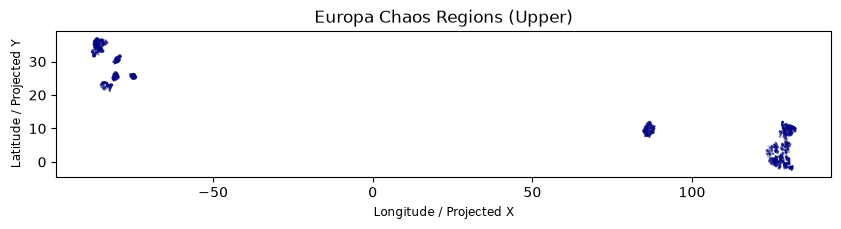

In [15]:
# plot the entire dataset on its native Europa coordinate system
fig, ax = plt.subplots(figsize=(10, 8))
gdf_upper.plot(ax=ax, color="lightblue", edgecolor="navy", alpha=0.7)
ax.set_title("Europa Chaos Regions (Upper)")
ax.set_xlabel("Longitude / Projected X")
ax.set_ylabel("Latitude / Projected Y")
plt.show()

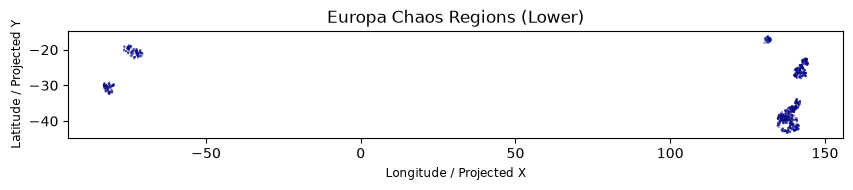

In [16]:
# plot the entire dataset on its native Europa coordinate system
fig, ax = plt.subplots(figsize=(10, 8))
gdf_lower.plot(ax=ax, color="lightblue", edgecolor="navy", alpha=0.7)
ax.set_title("Europa Chaos Regions (Lower)")
ax.set_xlabel("Longitude / Projected X")
ax.set_ylabel("Latitude / Projected Y")
plt.show()

In [27]:
print("Chaos regions in upper:" )
for letter in gdf_upper['Chaos_Lett'].unique():
    if letter == 'NULL':
        continue
    print(f" - {letter}")
print("Chaos regions in lower:" )
for letter in gdf_lower['Chaos_Lett'].unique():
    if letter == 'NULL':
        continue
    print(f" - {letter}")

Chaos regions in upper:
 - B
 - A
 - D
 - C
 - nan
 - E
Chaos regions in lower:
 - I
 - H
 - G
 - F
 - kk
 - jj
 - ii
 - hh
 - ff
 - ee
 - gg


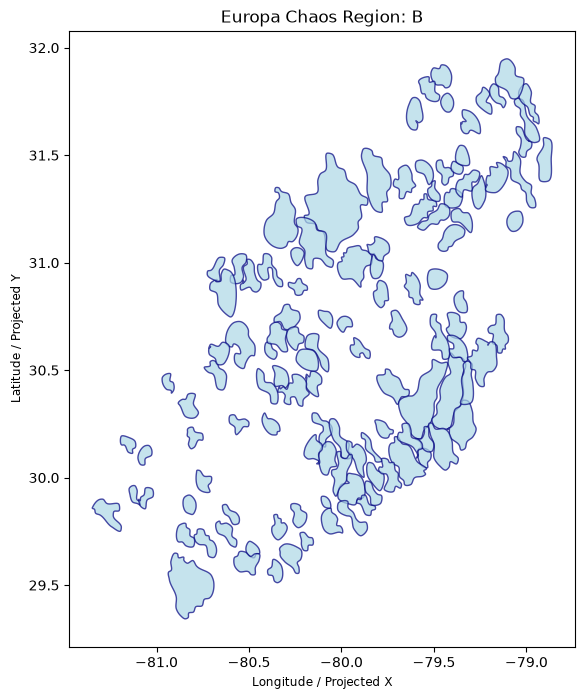

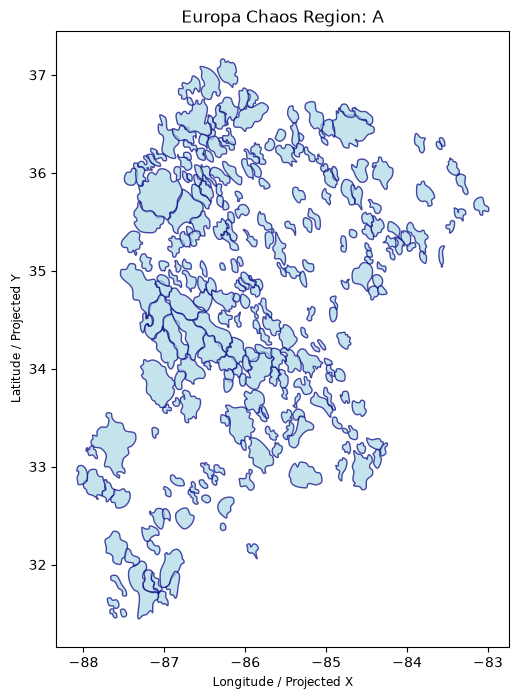

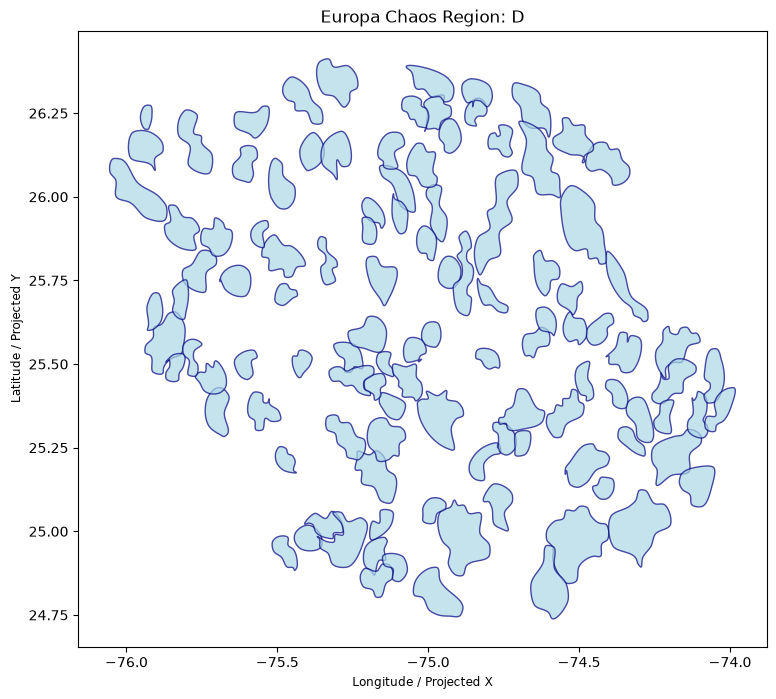

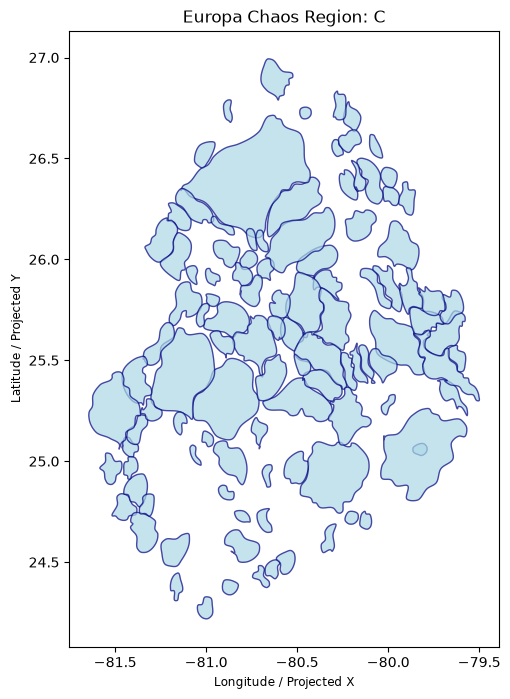

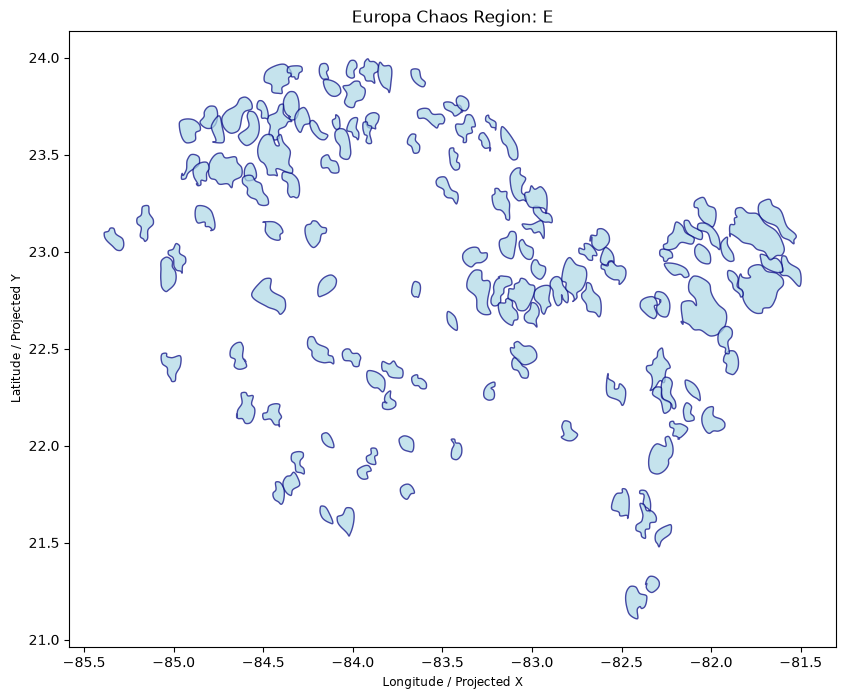

In [28]:
# plot each chaoas region based on Chaos_Lett column
valid_letters = gdf_upper['Chaos_Lett'].dropna().unique()

for letter in valid_letters:
    fig, ax = plt.subplots(figsize=(10, 8))
    gdf_upper[gdf_upper['Chaos_Lett'] == letter].plot(ax=ax, color="lightblue", edgecolor="navy", alpha=0.7)
    ax.set_title(f"Europa Chaos Region: {letter}")
    ax.set_xlabel("Longitude / Projected X")
    ax.set_ylabel("Latitude / Projected Y")
    plt.show()


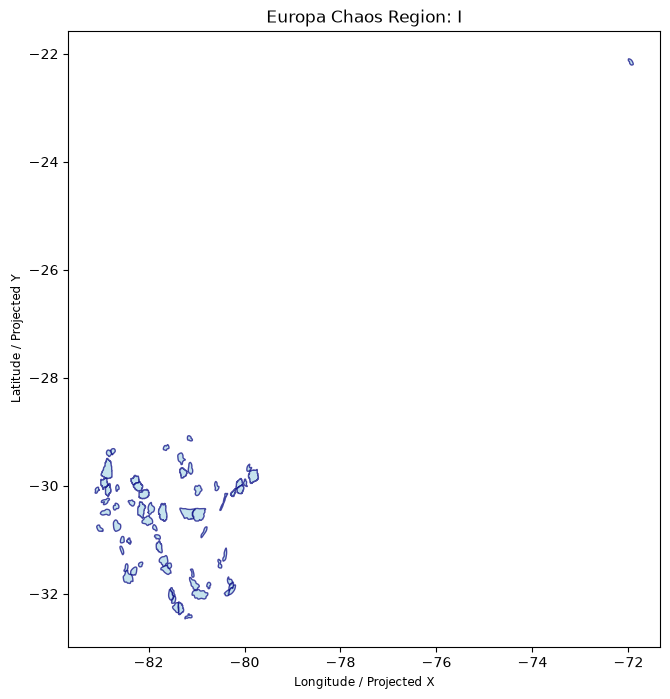

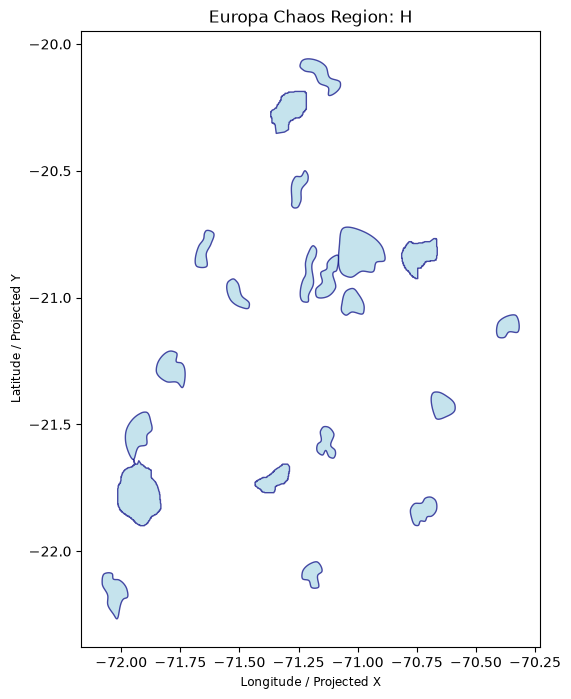

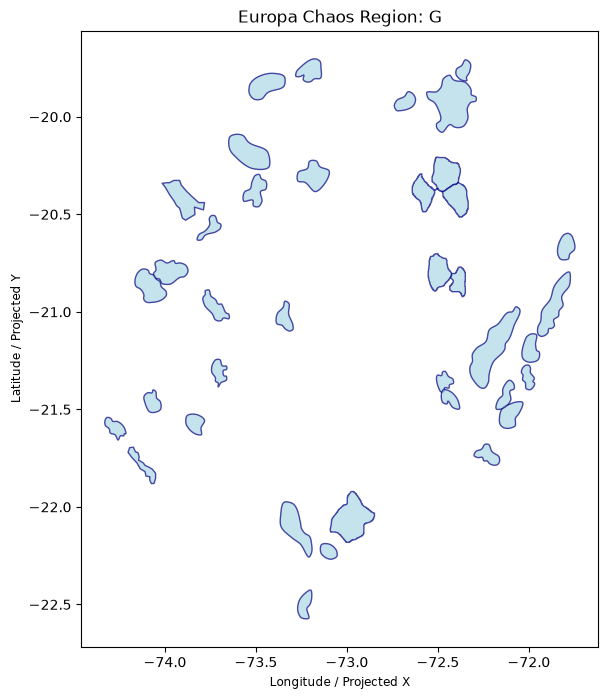

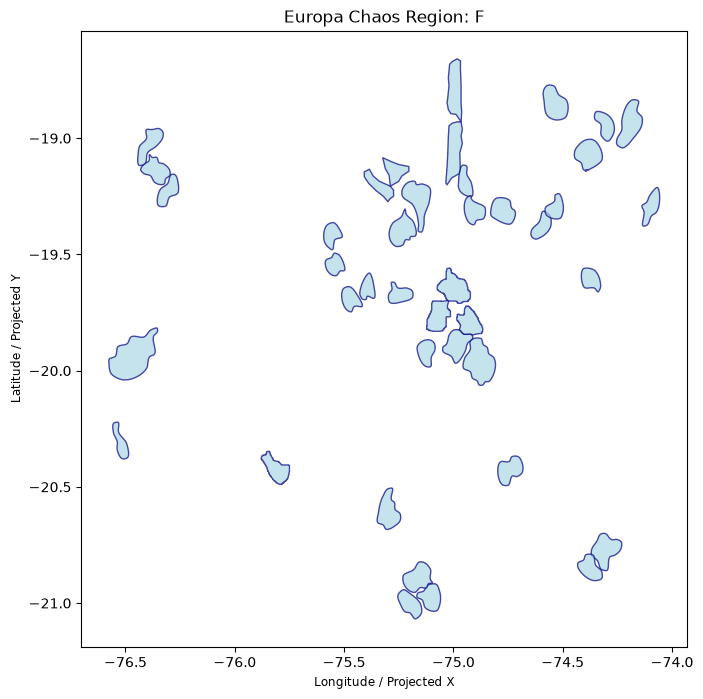

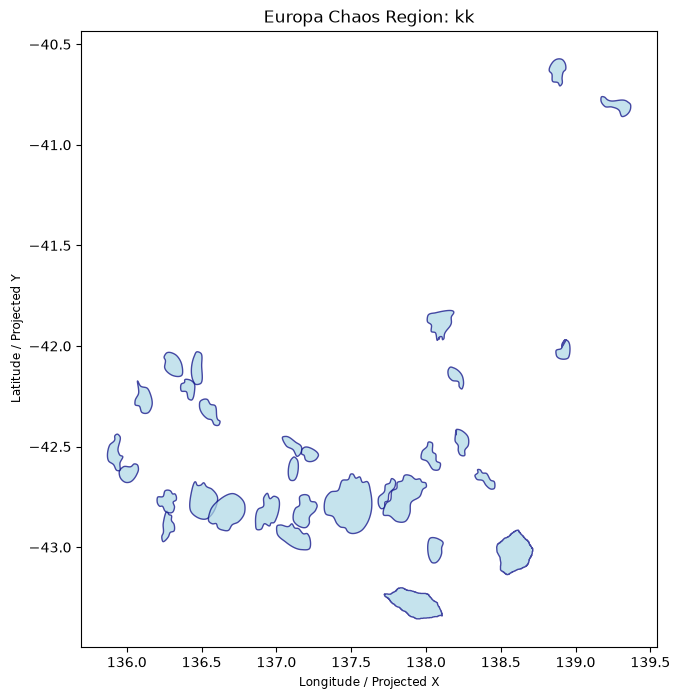

...

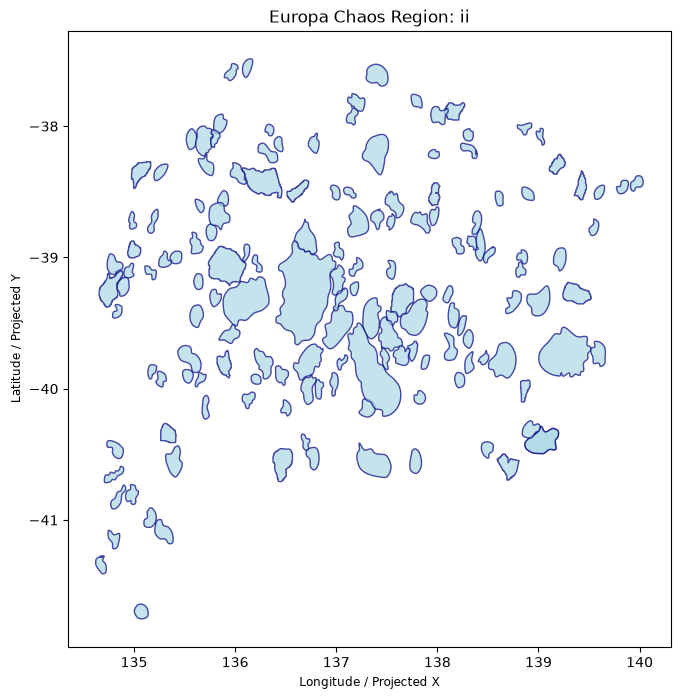

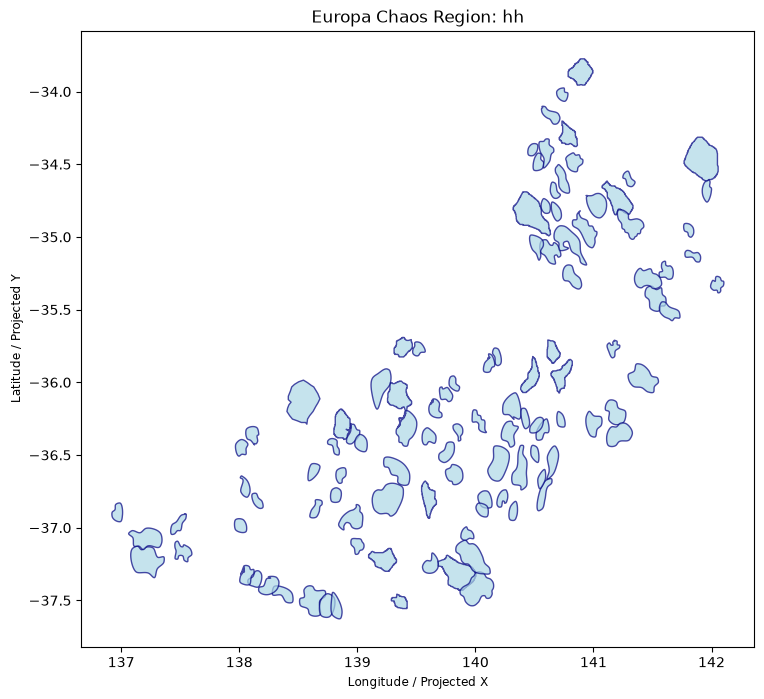

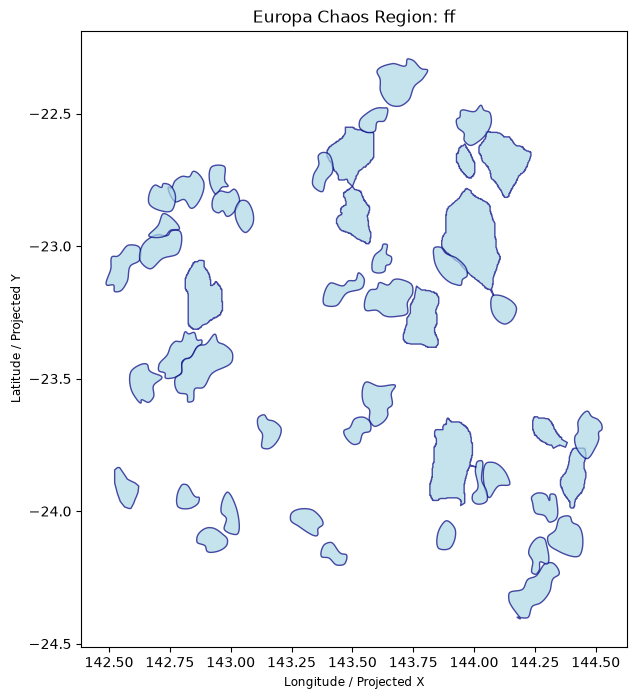

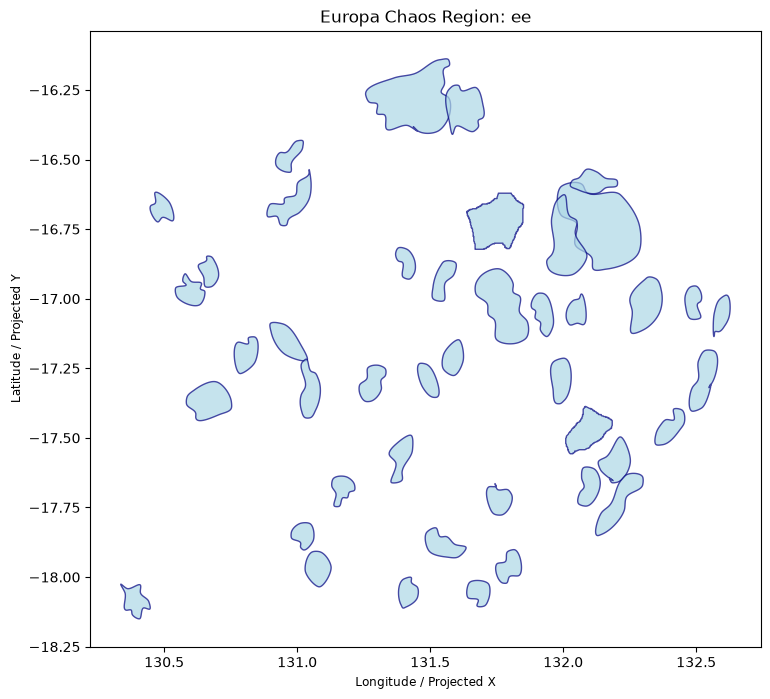

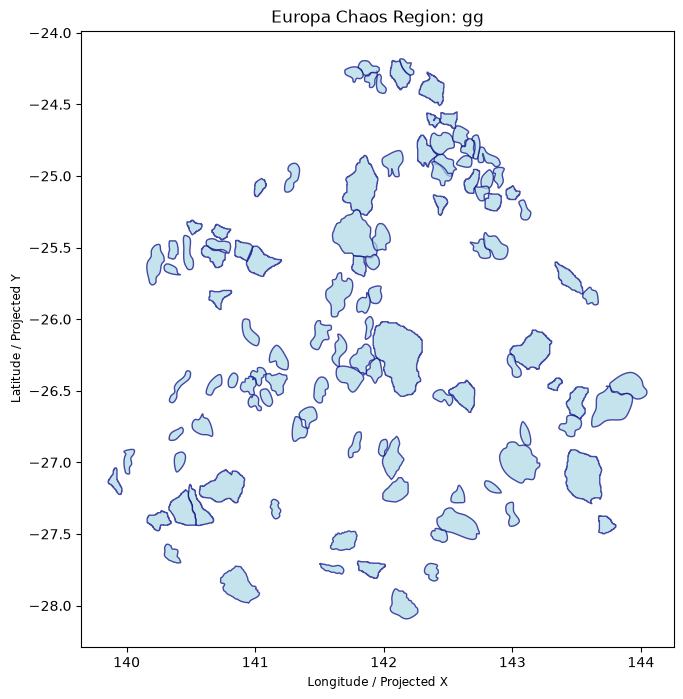

In [29]:
# plot each chaoas region based on Chaos_Lett column
valid_letters = gdf_lower['Chaos_Lett'].dropna().unique()

for letter in valid_letters:
    fig, ax = plt.subplots(figsize=(10, 8))
    gdf_lower[gdf_lower['Chaos_Lett'] == letter].plot(ax=ax, color="lightblue", edgecolor="navy", alpha=0.7)
    ax.set_title(f"Europa Chaos Region: {letter}")
    ax.set_xlabel("Longitude / Projected X")
    ax.set_ylabel("Latitude / Projected Y")
    plt.show()

In [4]:
# import geojson files
geojson_files = [f for f in os.listdir(geojson_folder) if f.endswith('.json')]

print("geojson files found:", geojson_files)

geojson files found: ['Chaos_jj.json', 'Chaos_C.json', 'Chaos_B.json', 'Chaos_Co.json', 'Chaos_dd.json', 'Chaos_bb.json', 'Chaos_E.json', 'Chaos_ee.json', 'Chaos_I.json', 'Chaos_H.json', 'Chaos_kk.json', 'Chaos_D.json', 'Chaos_gg.json', 'Chaos_G.json', 'Chaos_F.json', 'Chaos_ii.json', 'Chaos_hh.json', 'Chaos_A.json', 'Chaos_ff.json', 'Chaos_aa.json']


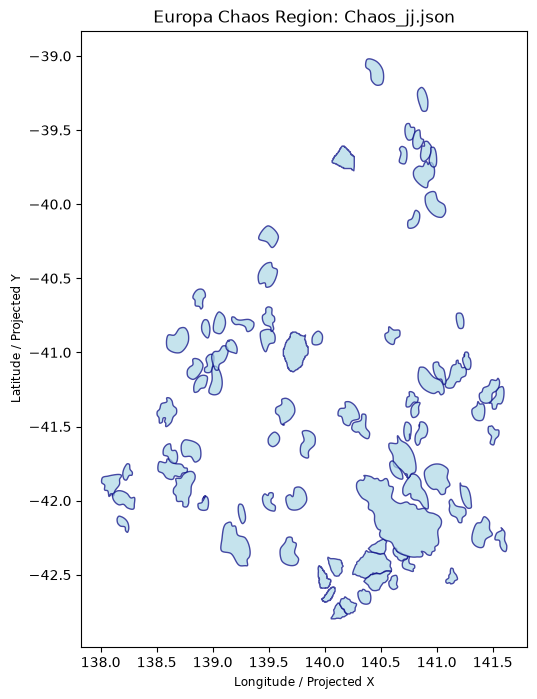

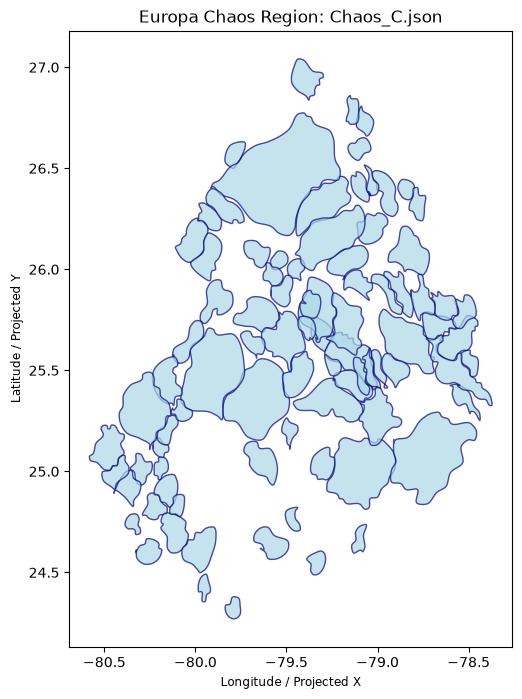

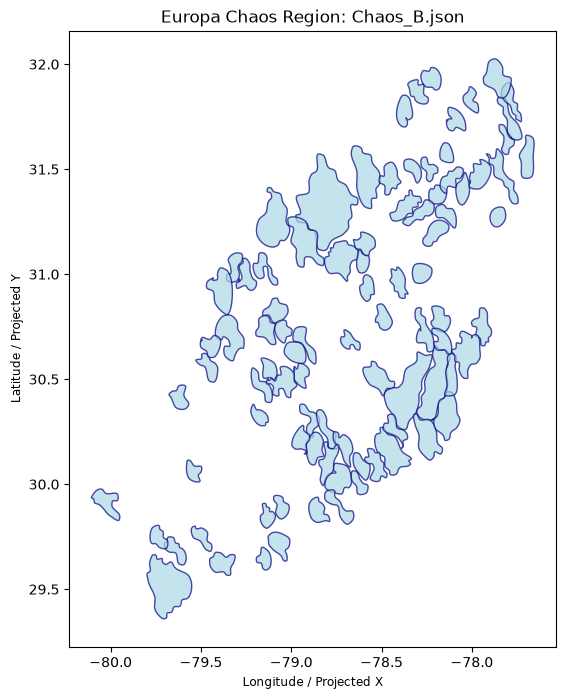

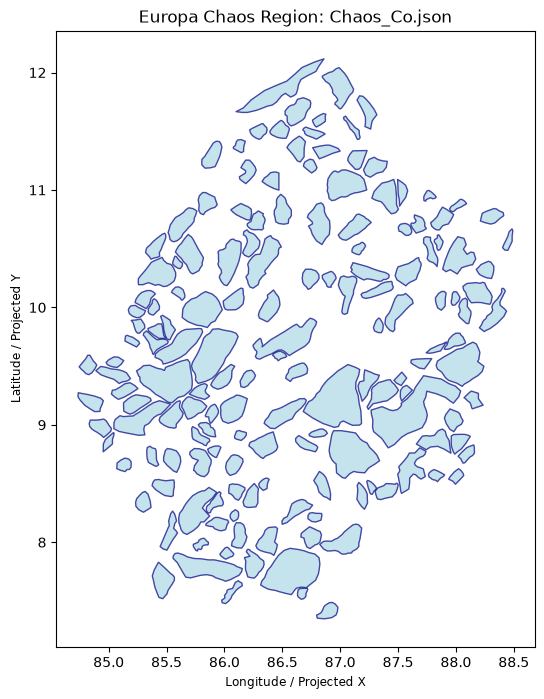

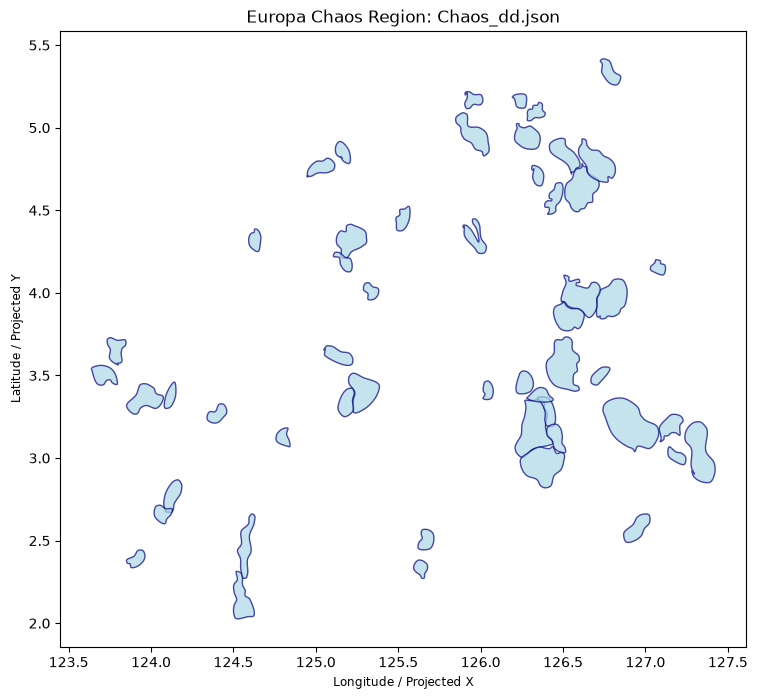

...

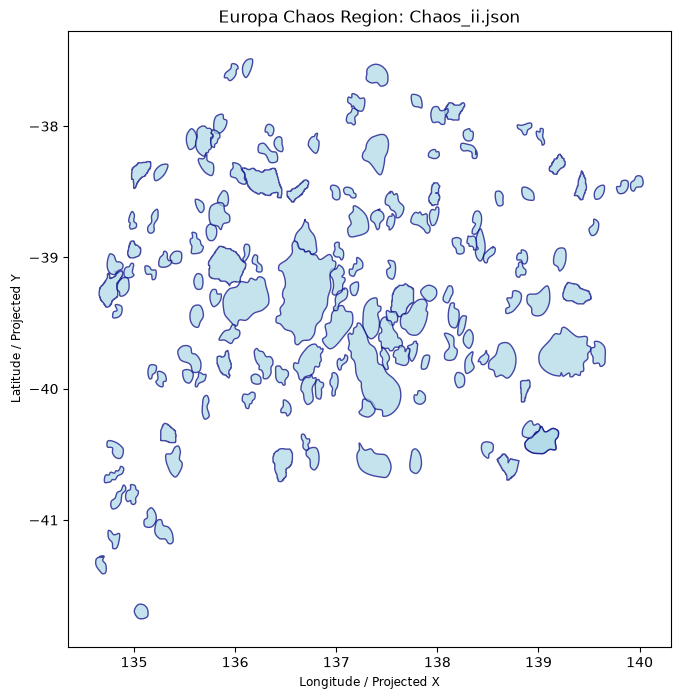

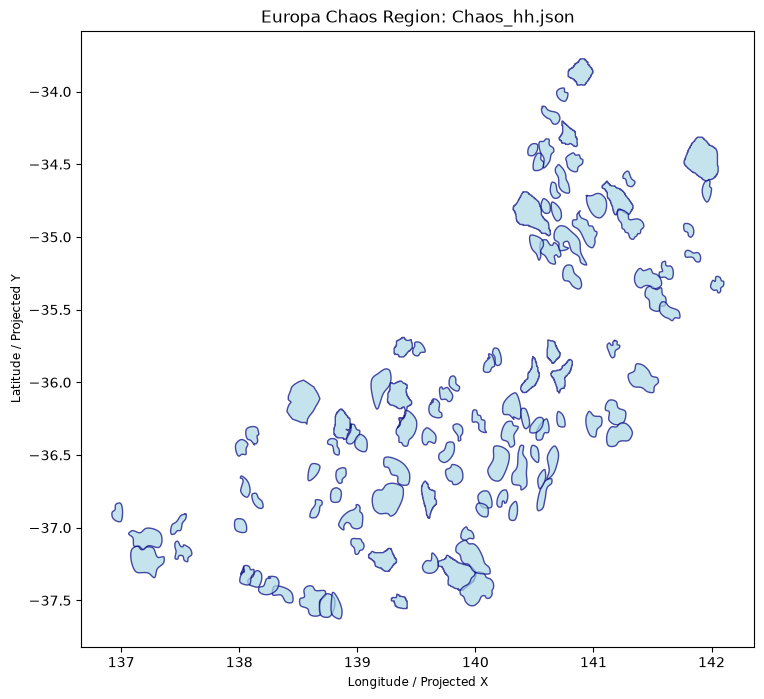

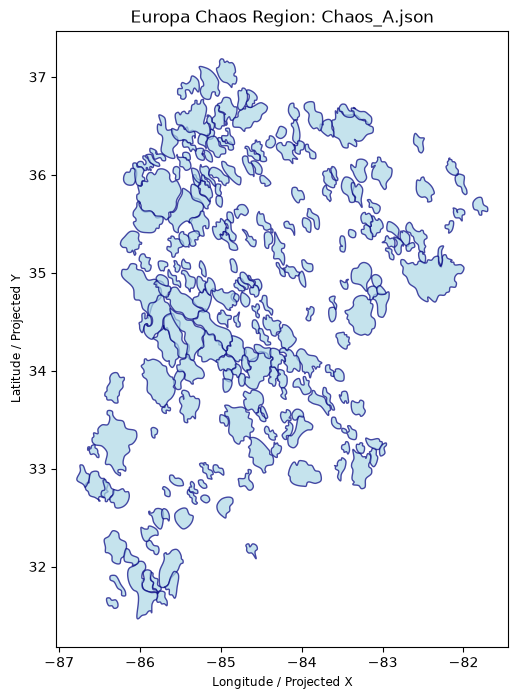

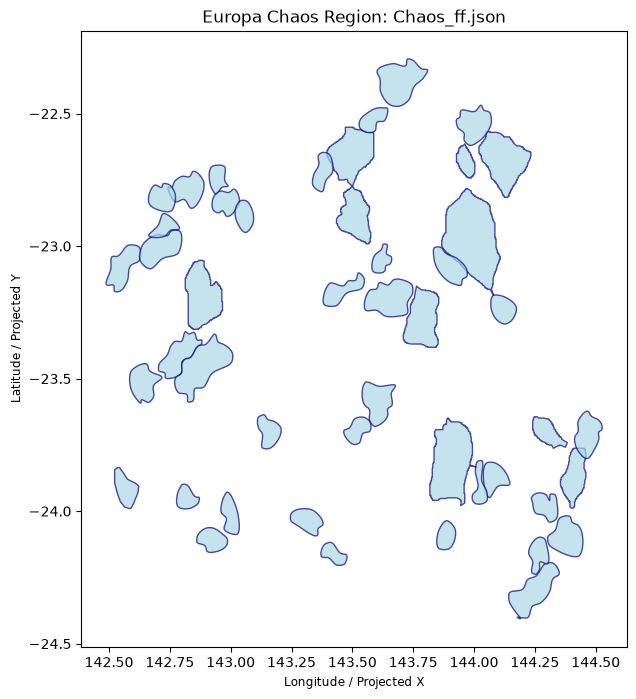

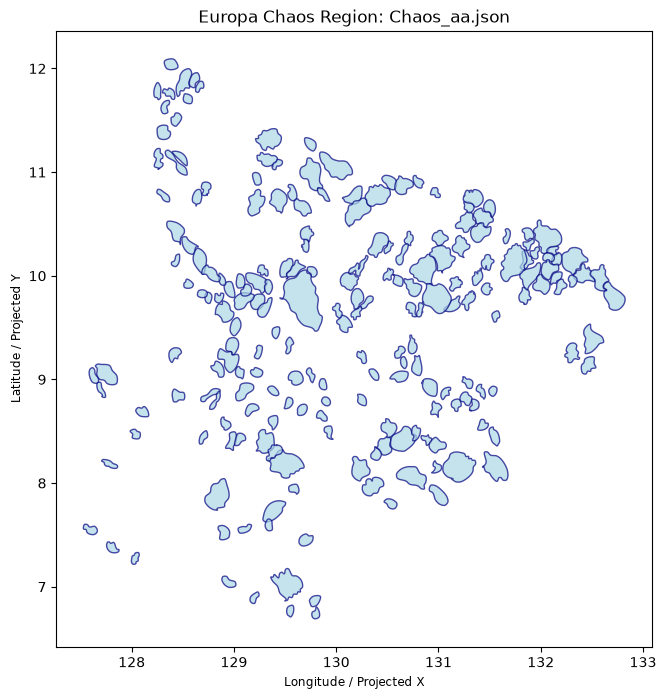

In [5]:
# plot the geojson files
for file in geojson_files:
    gdf = gpd.read_file(os.path.join(geojson_folder, file))
    fig, ax = plt.subplots(figsize=(10, 8))
    gdf.plot(ax=ax, color="lightblue", edgecolor="navy", alpha=0.7)
    ax.set_title(f"Europa Chaos Region: {file}")
    ax.set_xlabel("Longitude / Projected X")
    ax.set_ylabel("Latitude / Projected Y")
    plt.show()

In [3]:
def build_tiff_index(tiff_dir):

    records = []
    # store the paths, bounds, and CRS of everyy TIFF in a list
    for tif in sorted(glob.glob(os.path.join(tiff_dir, "*.tif"))):
        with rasterio.open(tif) as src:
            records.append({
                "tiff_path": tif,
                "crs": src.crs,
                "bounds": box(*src.bounds)
            })
    return records

def view_overlay_regions(geojson_dir, tiff_dir, region_crs = "ESRI:104915"):

    # build a list of the TIFFs from the directory
    tiffs = build_tiff_index(tiff_dir)

    # loop through the geojson files
    for json in sorted(glob.glob(os.path.join(geojson_dir, "*.json"))):
        region = gpd.read_file(json)
        region_name = os.path.splitext(os.path.basename(json))[0]

        # assign a CRS if the geojson had none
        if region.crs is None:
            region = region.set_crs(region_crs)

        matched_any = False

        # check overlap in the same CRS
        for tinfo in tiffs:
            tif = tinfo["tiff_path"]
            tif_crs = tinfo["crs"]
            tif_bounds = tinfo["bounds"]

            # project the region's geometry to this specific TIFF's CRS
            region_proj = region.to_crs(tif_crs) if tif_crs else region
            region_bounds = box(*region_proj.total_bounds)

            # I=if the boxes don't overlap, skip to the next TIFF
            if not region_bounds.intersects(tif_bounds):
                continue
            
            matched_any = True

            # plot the choas on top of the TIFF
            with rasterio.open(tif) as src:
                # add padding for visual context
                minx, miny, maxx, maxy = region_proj.total_bounds
                pad_x, pad_y = (maxx - minx) * 0.2, (maxy - miny) * 0.2
                
                # crop exactly to this region
                window = from_bounds(
                    minx - pad_x, miny - pad_y, 
                    maxx + pad_x, maxy + pad_y, 
                    transform=src.transform
                )
                
                img_data = src.read(1, window=window, boundless=True).astype(np.float32)
                win_transform = src.window_transform(window)
                
                # clean the data
                if src.nodata is not None:
                    img_data[img_data == src.nodata] = np.nan
                img_data[np.isinf(img_data)] = np.nan
                img_data[img_data < -1e30] = np.nan
                img_data[img_data > 1e30] = np.nan
                
                if np.isnan(img_data).all():
                    print(f"[WARN] Zoomed area is empty NoData for {region_name}")
                    continue
                
                # use 2nd and 98th percentiles for contrast
                vmin, vmax = np.nanpercentile(img_data, [2, 98])
                if vmin == vmax:
                    vmin, vmax = np.nanmin(img_data), np.nanmax(img_data)
                
                # plot
                fig, ax = plt.subplots(figsize=(10, 8))
                show(img_data, ax=ax, cmap="gray", transform=win_transform, vmin=vmin, vmax=vmax)                      
                region_proj.boundary.plot(ax=ax, color="yellow", linewidth=2.0)

                ax.set_title(f"{region_name} on {os.path.basename(tif)}")
                plt.show()
                print(f"[OK] Displayed {region_name} -> {os.path.basename(tif)}")

        

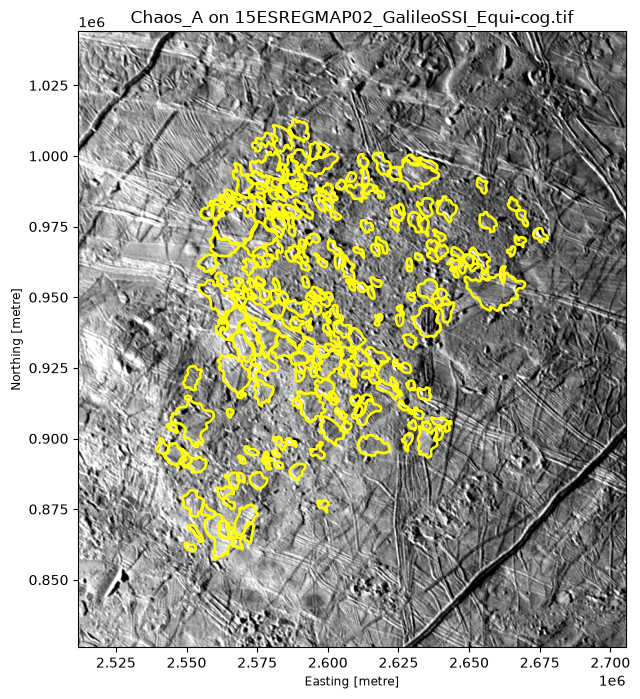

[OK] Displayed Chaos_A -> 15ESREGMAP02_GalileoSSI_Equi-cog.tif


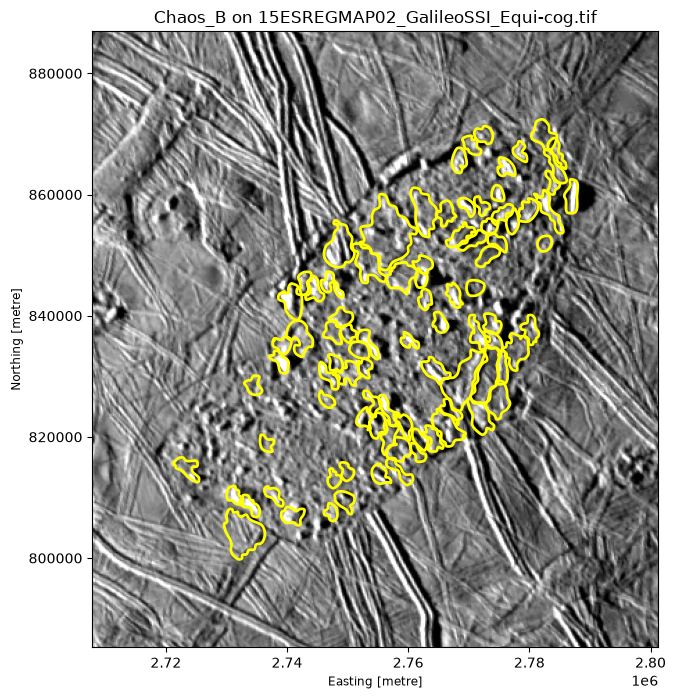

[OK] Displayed Chaos_B -> 15ESREGMAP02_GalileoSSI_Equi-cog.tif


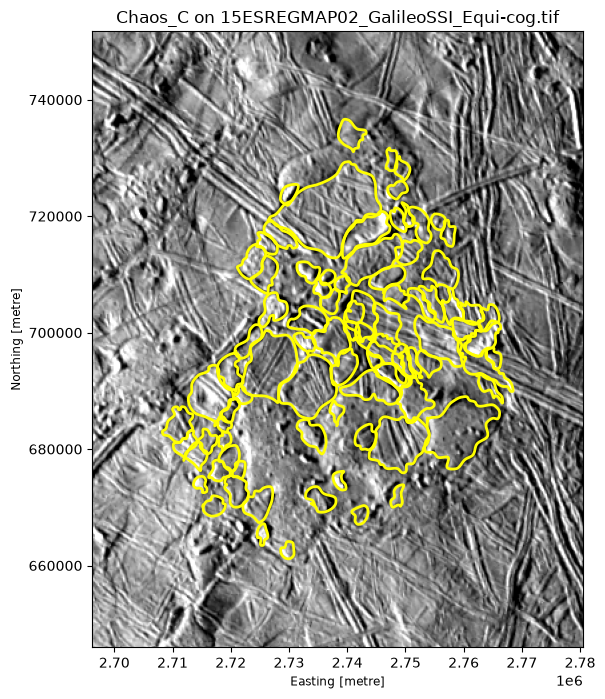

[OK] Displayed Chaos_C -> 15ESREGMAP02_GalileoSSI_Equi-cog.tif


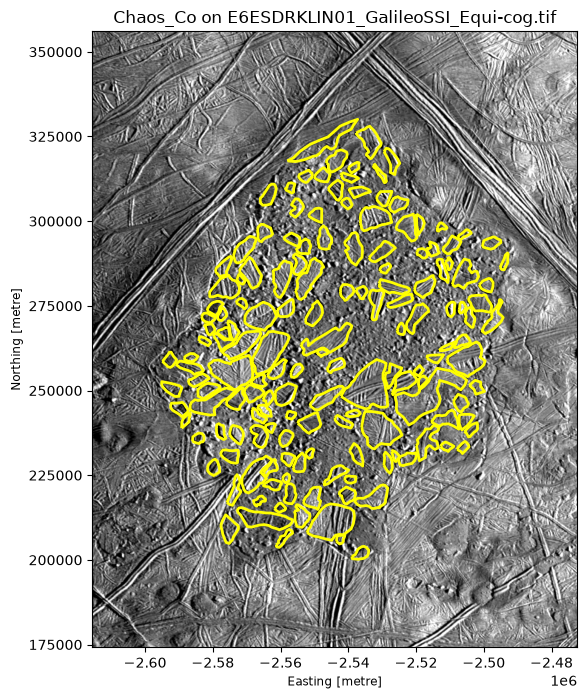

[OK] Displayed Chaos_Co -> E6ESDRKLIN01_GalileoSSI_Equi-cog.tif


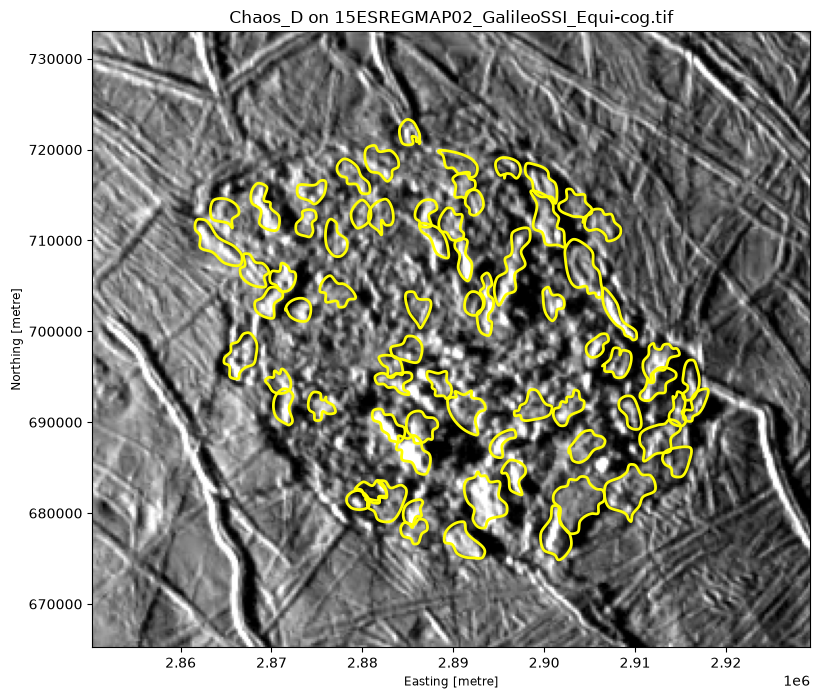

[OK] Displayed Chaos_D -> 15ESREGMAP02_GalileoSSI_Equi-cog.tif


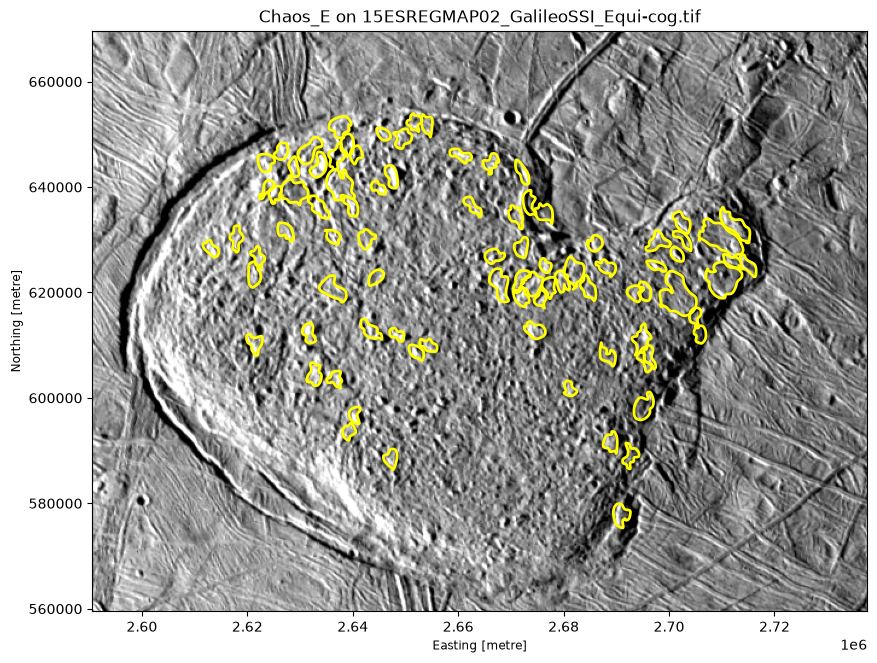

[OK] Displayed Chaos_E -> 15ESREGMAP02_GalileoSSI_Equi-cog.tif


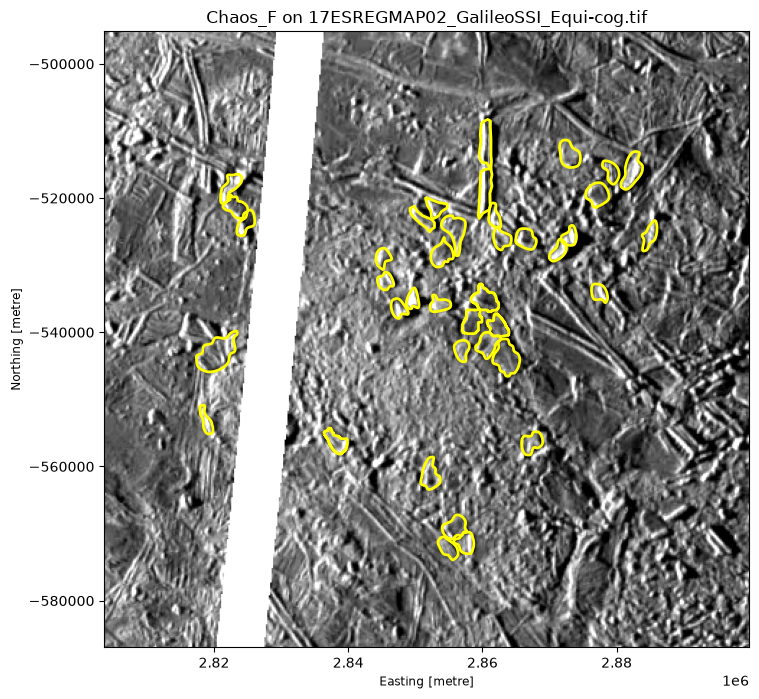

[OK] Displayed Chaos_F -> 17ESREGMAP02_GalileoSSI_Equi-cog.tif


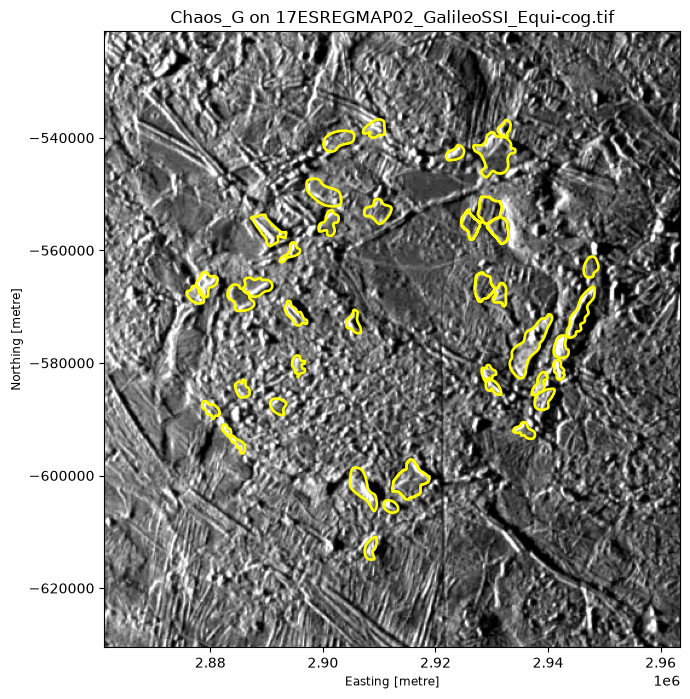

[OK] Displayed Chaos_G -> 17ESREGMAP02_GalileoSSI_Equi-cog.tif


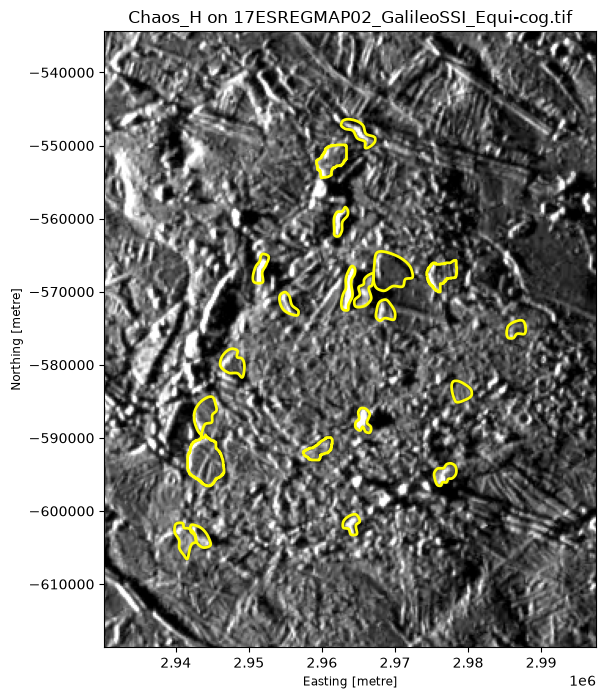

[OK] Displayed Chaos_H -> 17ESREGMAP02_GalileoSSI_Equi-cog.tif


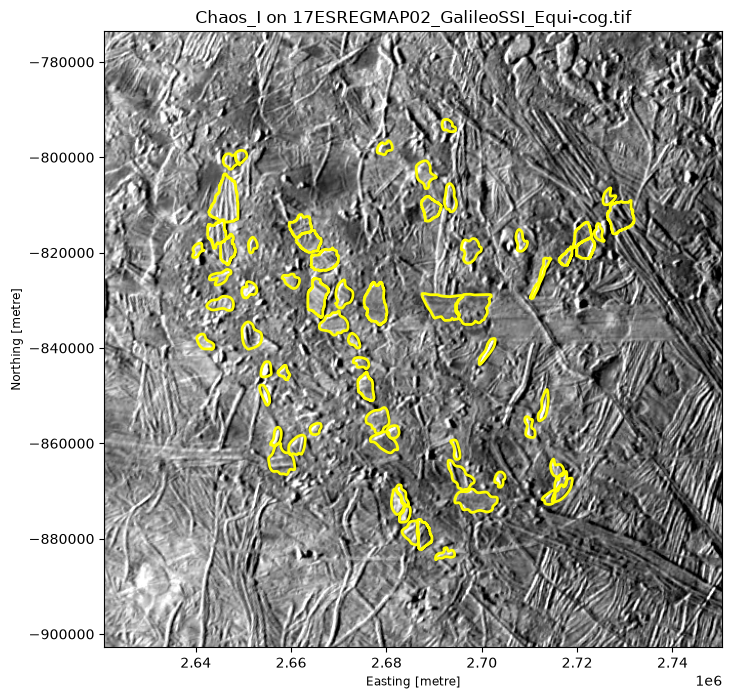

[OK] Displayed Chaos_I -> 17ESREGMAP02_GalileoSSI_Equi-cog.tif


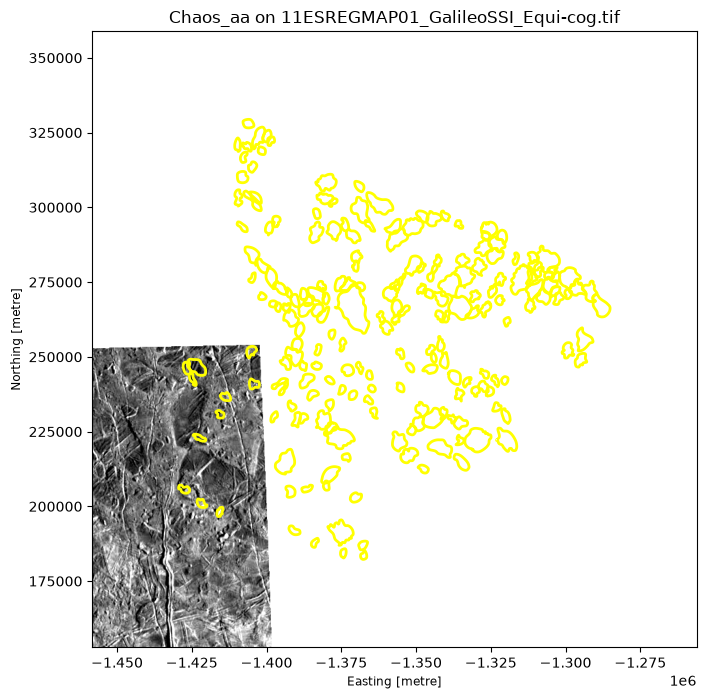

[OK] Displayed Chaos_aa -> 11ESREGMAP01_GalileoSSI_Equi-cog.tif


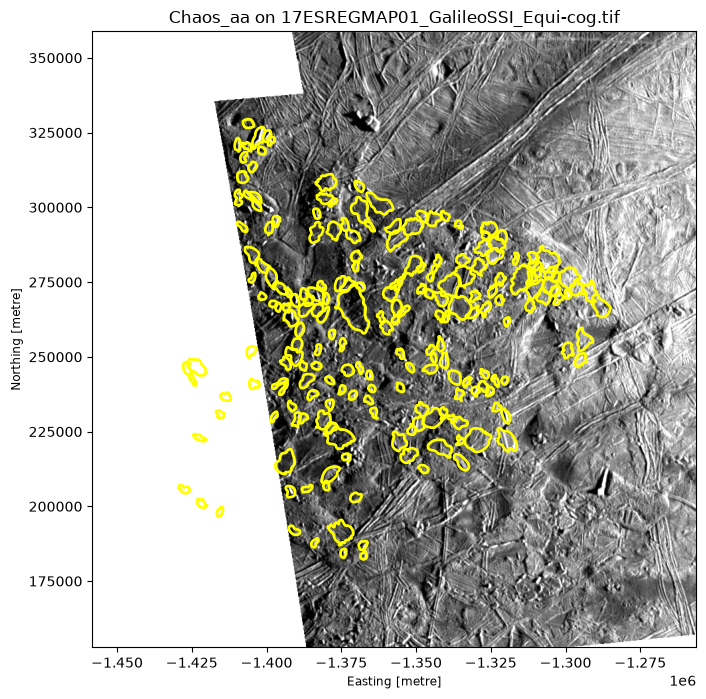

[OK] Displayed Chaos_aa -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


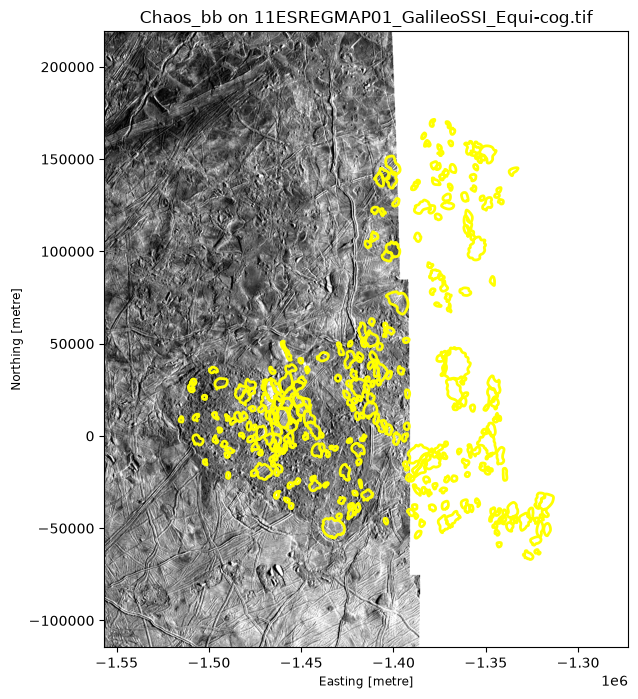

[OK] Displayed Chaos_bb -> 11ESREGMAP01_GalileoSSI_Equi-cog.tif


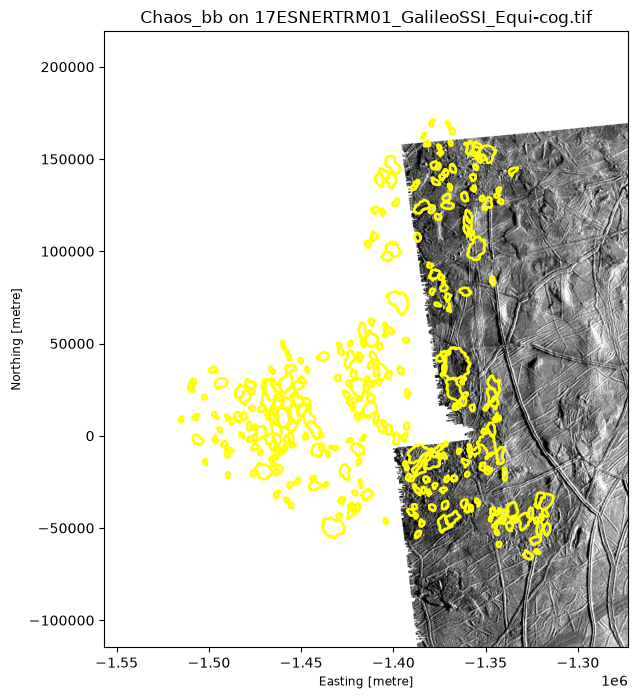

[OK] Displayed Chaos_bb -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif


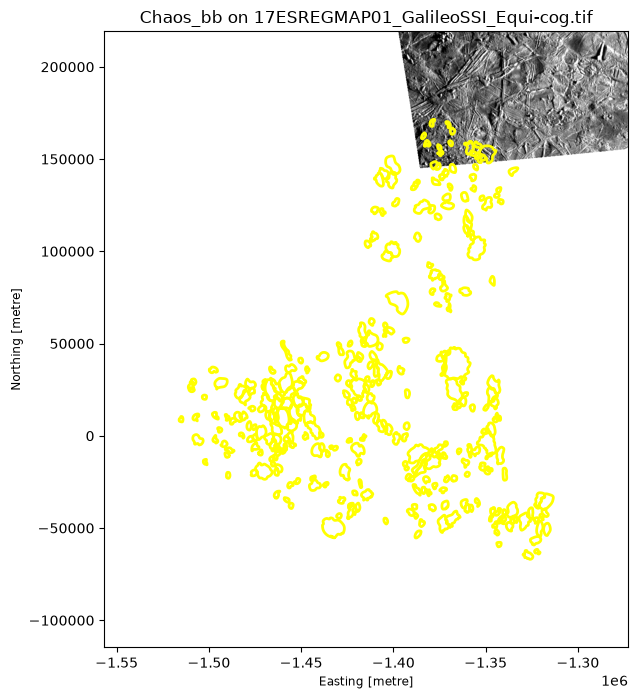

[OK] Displayed Chaos_bb -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


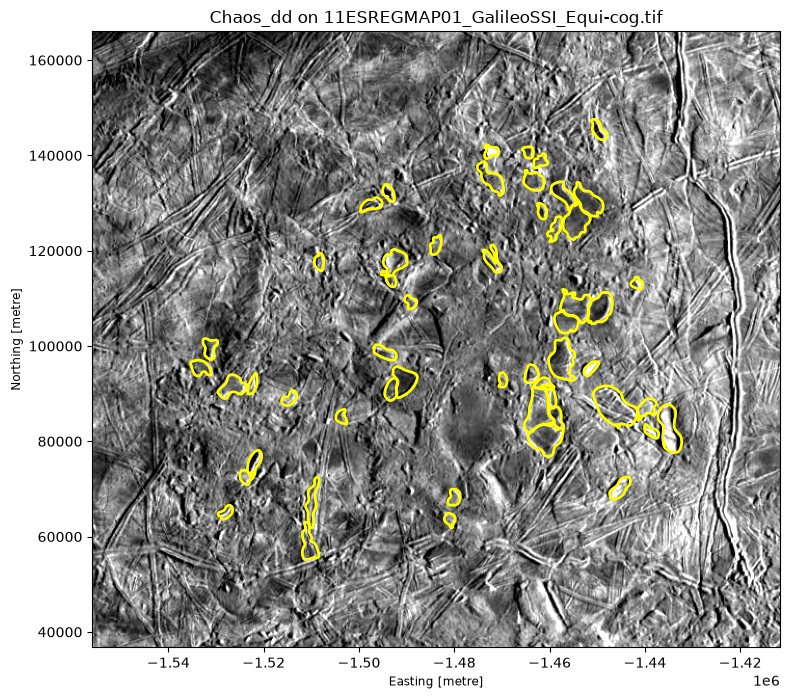

[OK] Displayed Chaos_dd -> 11ESREGMAP01_GalileoSSI_Equi-cog.tif


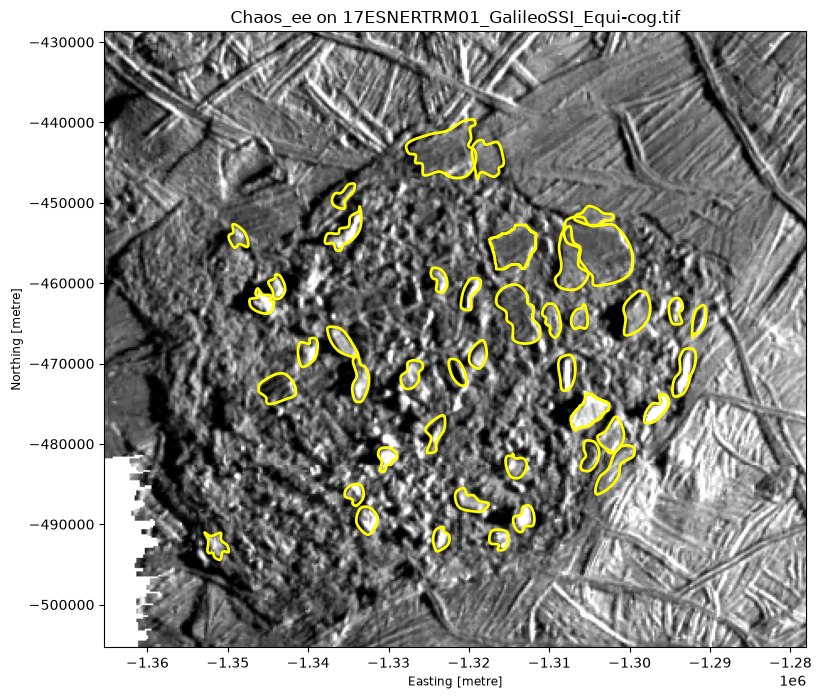

[OK] Displayed Chaos_ee -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif
[WARN] Zoomed area is empty NoData for Chaos_ee
[WARN] Zoomed area is empty NoData for Chaos_ff


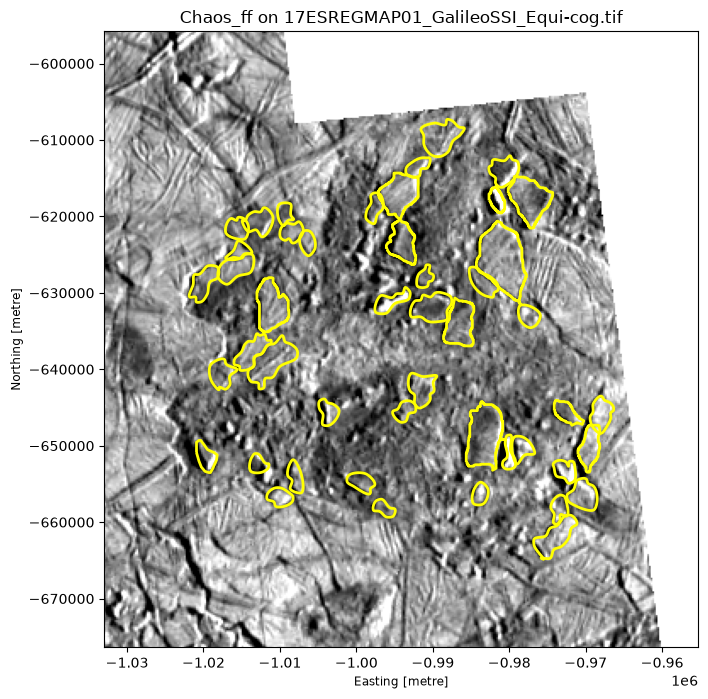

[OK] Displayed Chaos_ff -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


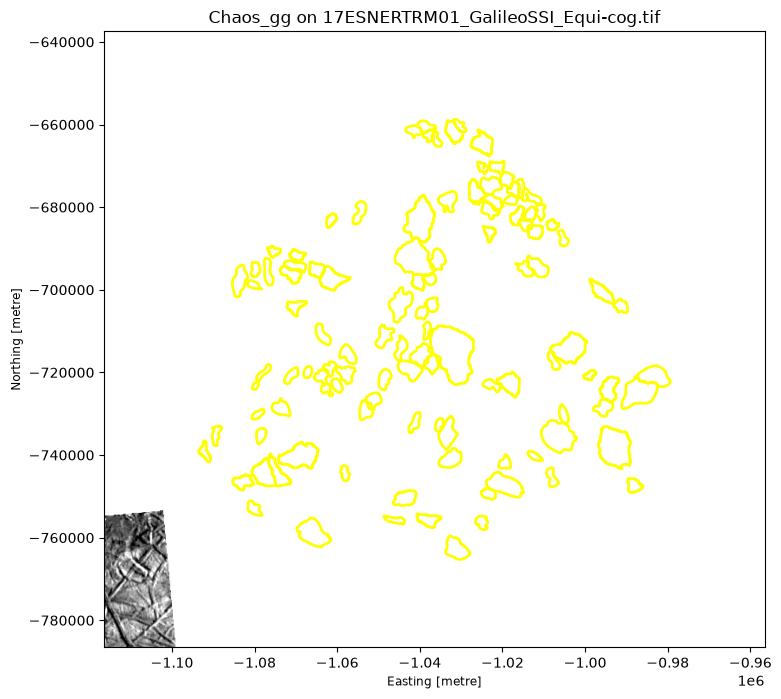

[OK] Displayed Chaos_gg -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif


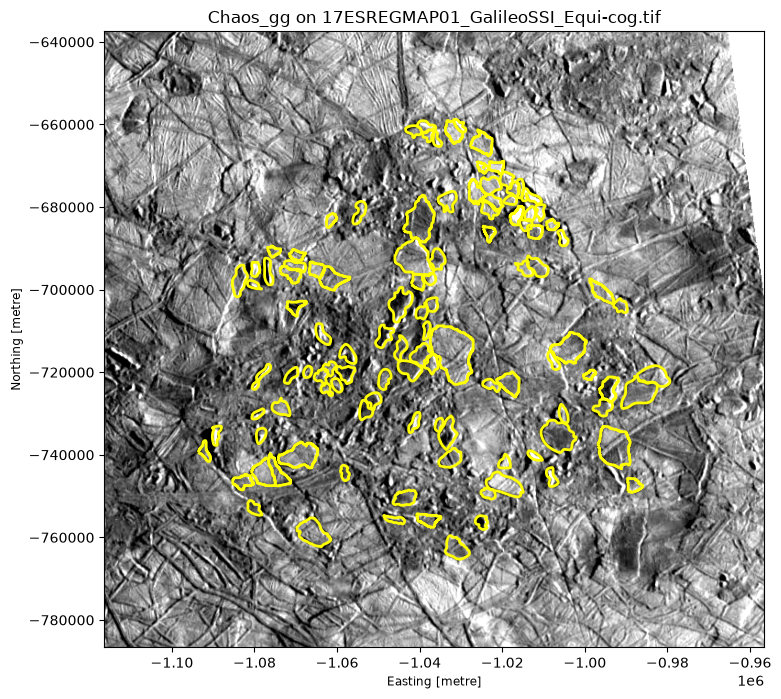

[OK] Displayed Chaos_gg -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


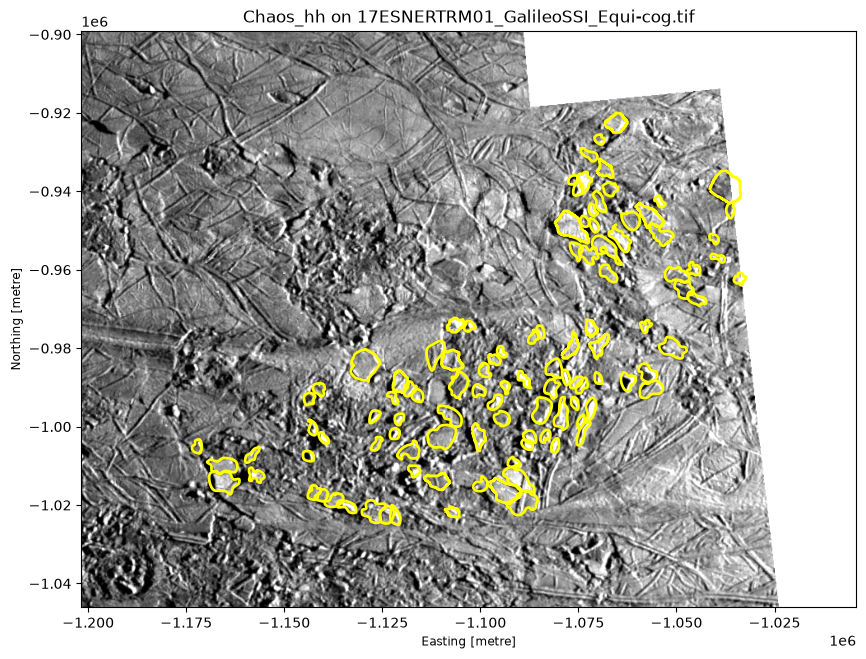

[OK] Displayed Chaos_hh -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif


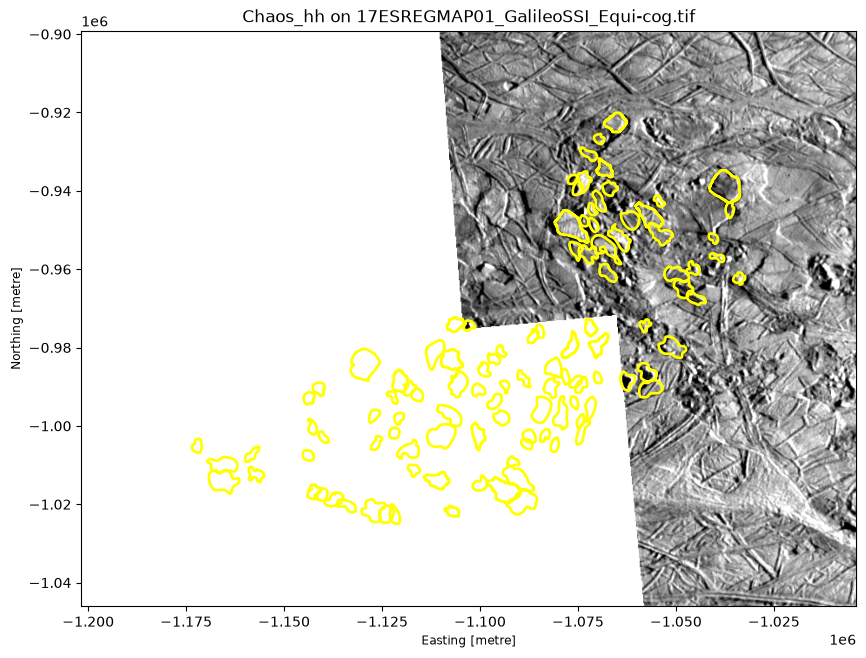

[OK] Displayed Chaos_hh -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


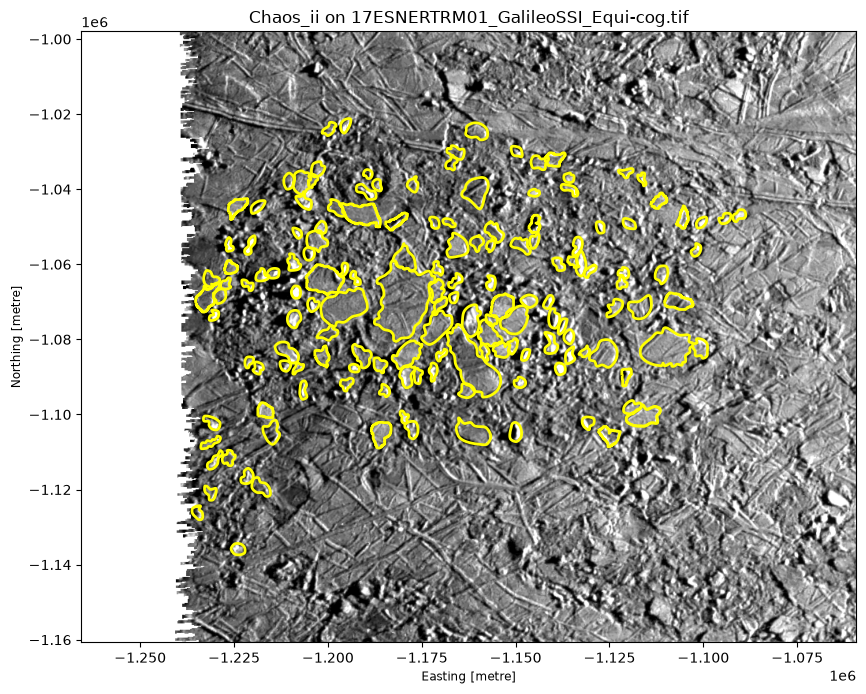

[OK] Displayed Chaos_ii -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif


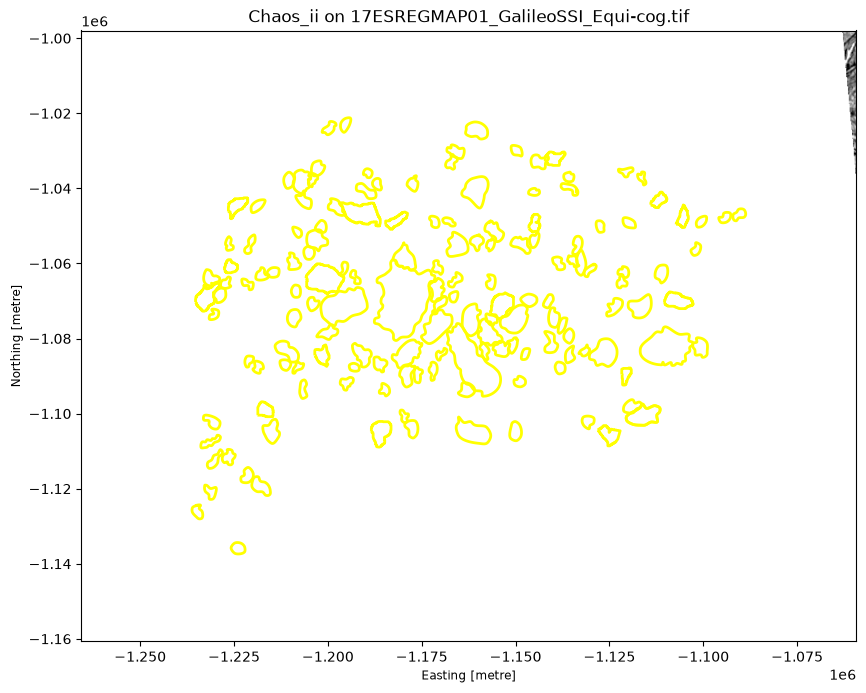

[OK] Displayed Chaos_ii -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


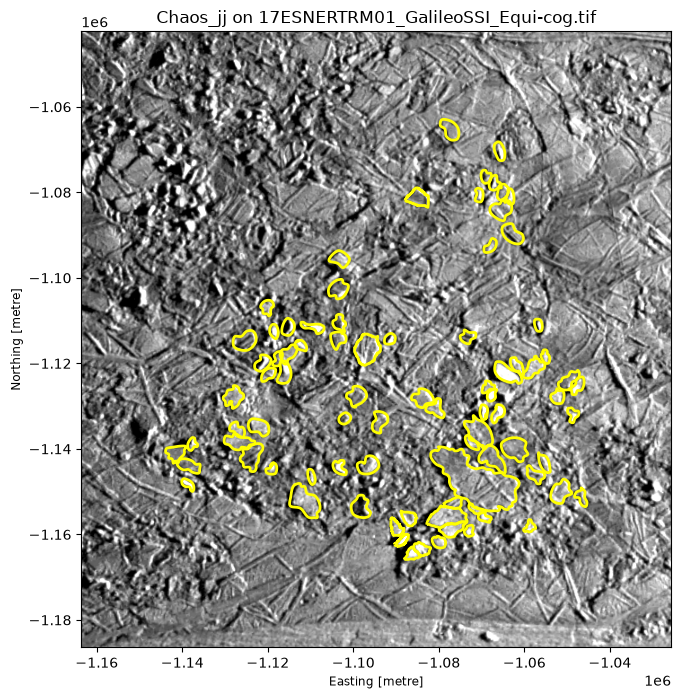

[OK] Displayed Chaos_jj -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif


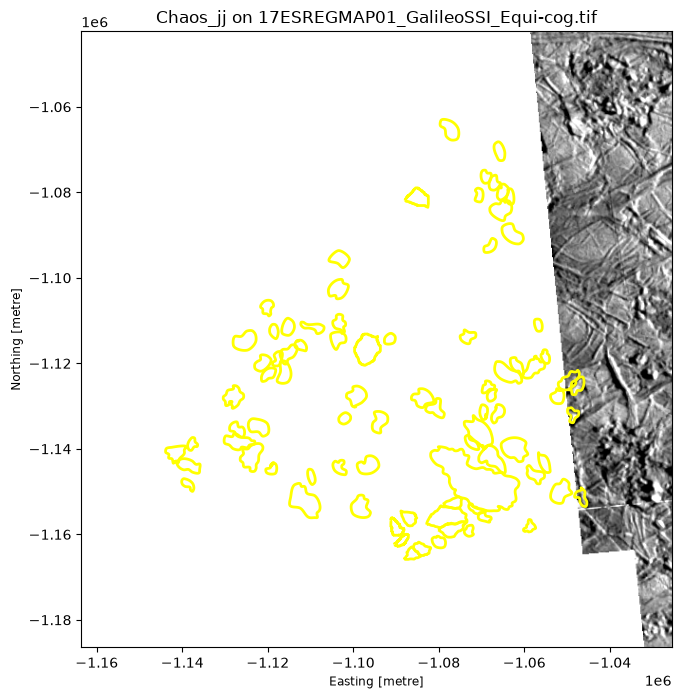

[OK] Displayed Chaos_jj -> 17ESREGMAP01_GalileoSSI_Equi-cog.tif


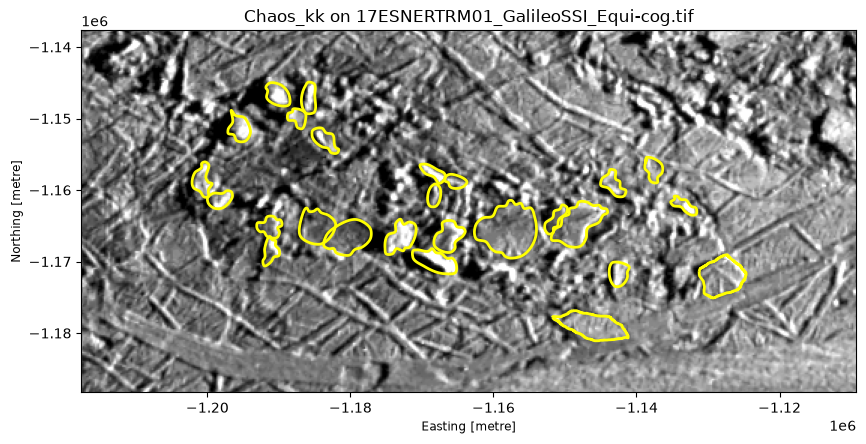

[OK] Displayed Chaos_kk -> 17ESNERTRM01_GalileoSSI_Equi-cog.tif
[WARN] Zoomed area is empty NoData for Chaos_kk


In [5]:
view_overlay_regions(
    geojson_dir="../data/raw/geojson_blocks",
    tiff_dir="../data/raw/tiff_images"
)

In [1]:
def view_stitched_images_and_masks(geojson_dir, tiff_dir, region_crs = "ESRI:104915"):
    tiffs = build_tiff_index(tiff_dir)

    for json in sorted(glob.glob(os.path.join(geojson_dir, "*.json"))):
        region = gpd.read_file(json)
        region_name = os.path.splitext(os.path.basename(json))[0]

        if region.crs is None:
            region = region.set_crs(region_crs)

        # find all TIFFs that intersect this region
        intersecting_tiffs = []
        target_crs = None
        
        for tinfo in tiffs:
            tif = tinfo["tiff_path"]
            tif_crs = tinfo["crs"]
            
            # project region to TIFF CRS to check intersection
            region_proj = region.to_crs(tif_crs) if tif_crs else region
            if box(*region_proj.total_bounds).intersects(tinfo["bounds"]):
                intersecting_tiffs.append(tif)
                target_crs = tif_crs # We will use the first matching TIFF's CRS

        if not intersecting_tiffs:
            print(f"no intersecting TIFFs found for {region_name}")
            continue
            
        # ensure region is in the final target CRS
        region = region.to_crs(target_crs) if target_crs else region

        # calculate bounding box for the stitched image
        minx, miny, maxx, maxy = region.total_bounds
        pad_x, pad_y = (maxx - minx) * 0.5, (maxy - miny) * 0.5
        stitch_bounds = (minx - pad_x, miny - pad_y, maxx + pad_x, maxy + pad_y)

        # open the TIFFs and stitch them together
        srcs_to_close = []
        try:
            for tif in intersecting_tiffs:
                srcs_to_close.append(rasterio.open(tif))
            
            # merge automatically stitches the arrays and calculates the new transform
            mosaic, out_trans = merge(srcs_to_close, bounds=stitch_bounds, nodata=np.nan)
        finally:
            # close the files to free up memory
            for src in srcs_to_close:
                src.close()

        # clean the stitched image data for viewing
        img_data = mosaic[0].astype(np.float32)
        img_data[img_data < -1e30] = np.nan
        img_data[img_data > 1e30] = np.nan
        
        if np.isnan(img_data).all():
            print(f"stitched area is empty NoData for {region_name}")
            continue

        # rasterize the json into a binary mask
        # give the shapes , the output dimensions, and the spatial transform
        shapes = ((geom, index + 1) for index, geom in enumerate(region.geometry))
        mask = rasterize(
            shapes=shapes,
            out_shape=img_data.shape,
            transform=out_trans,
            fill=0,            # Background is 0
            dtype='uint16'
        )

        # plot
        vmin, vmax = np.nanpercentile(img_data, [2, 98])
        
        fig, (ax_img, ax_mask) = plt.subplots(1, 2, figsize=(16, 8))
        
        # plot image
        show(img_data, ax=ax_img, cmap="gray", transform=out_trans, vmin=vmin, vmax=vmax)
        ax_img.set_title(f"{region_name} - Stitched Imagery")
        
        # plot mask
        show(mask, ax=ax_mask, cmap="viridis", transform=out_trans)
        ax_mask.set_title(f"{region_name} - ML Label Mask")
        
        plt.show()

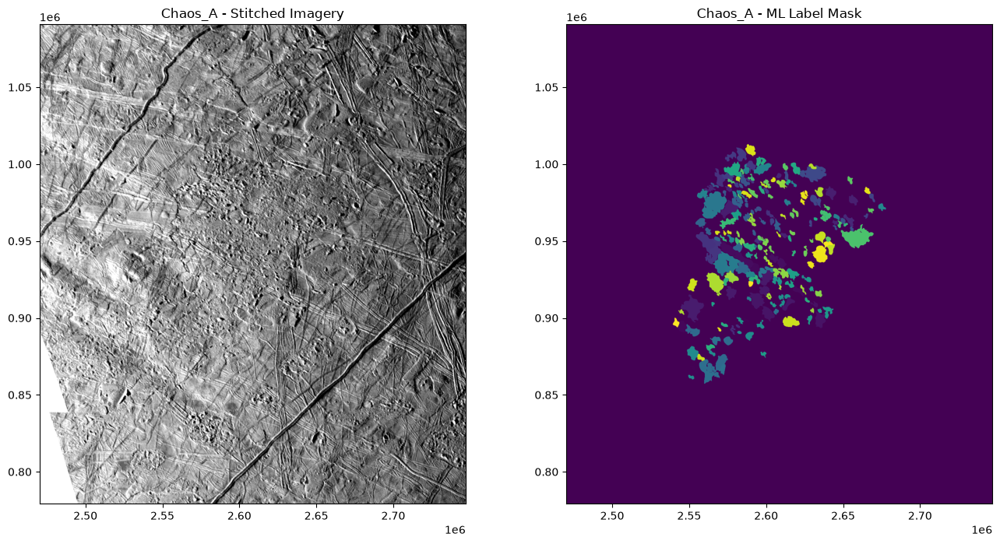

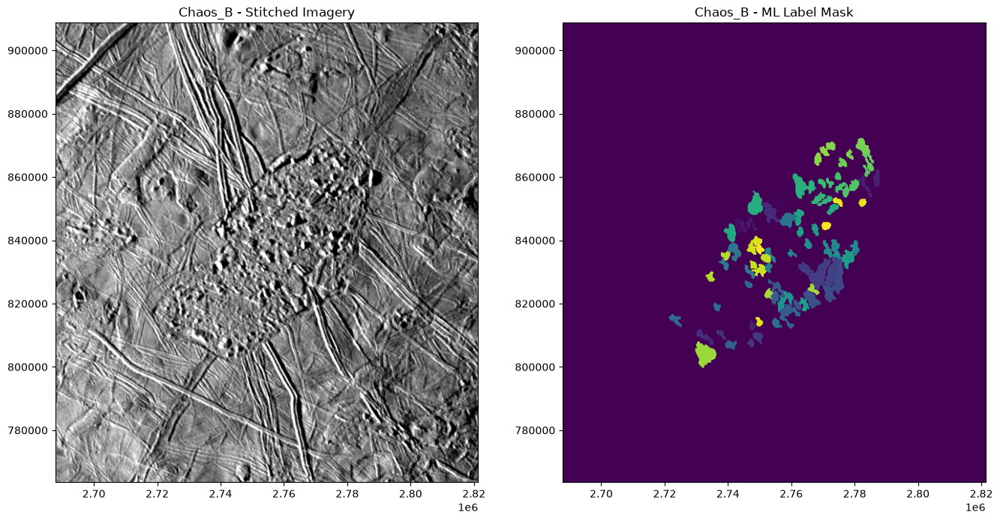

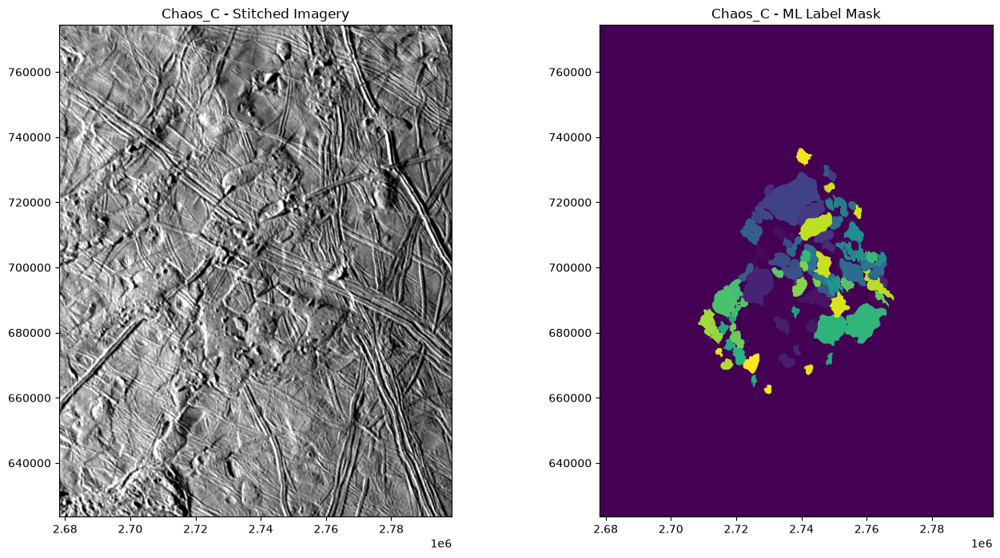

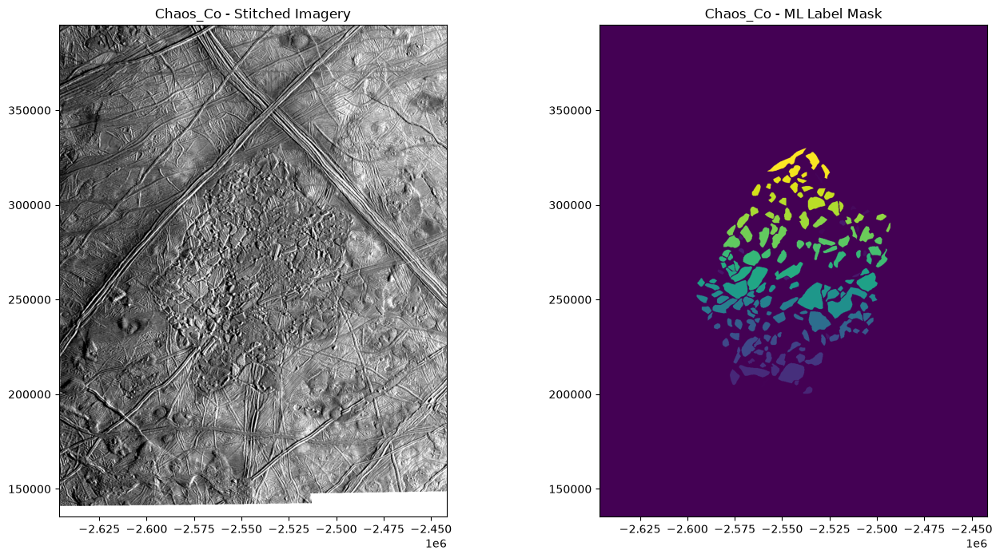

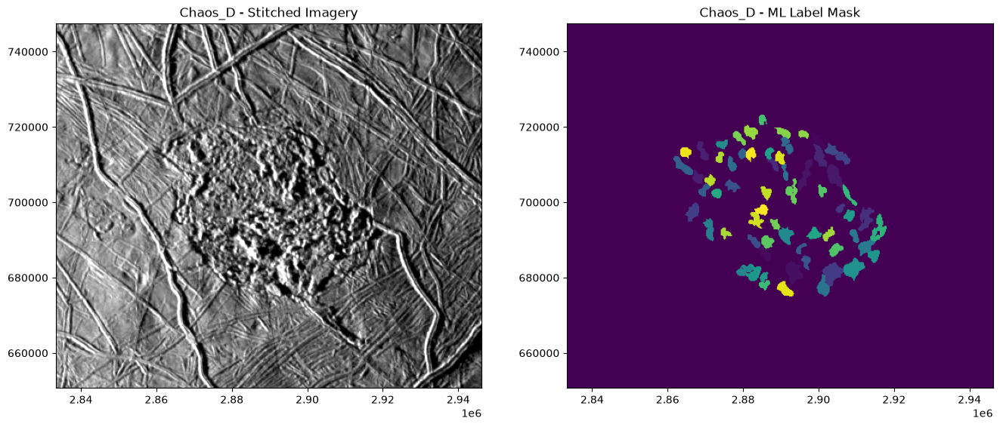

...

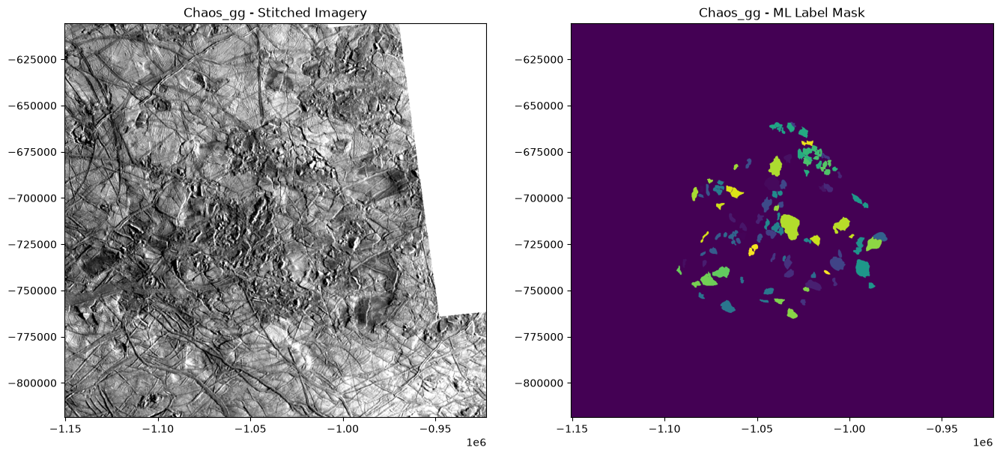

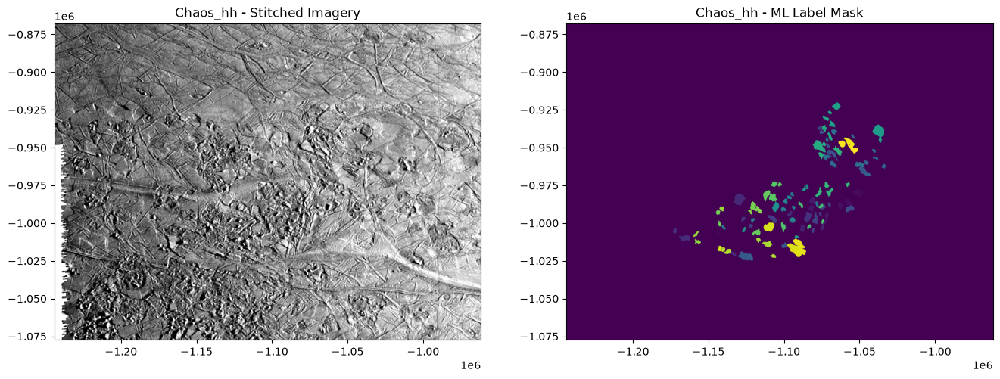

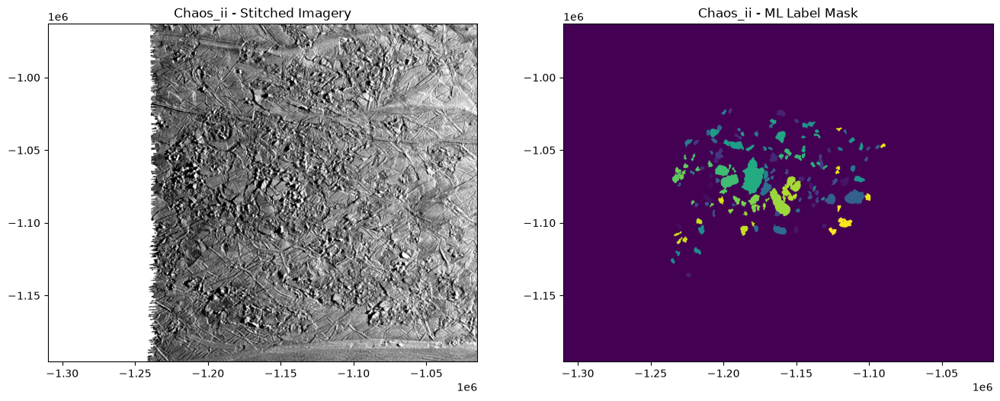

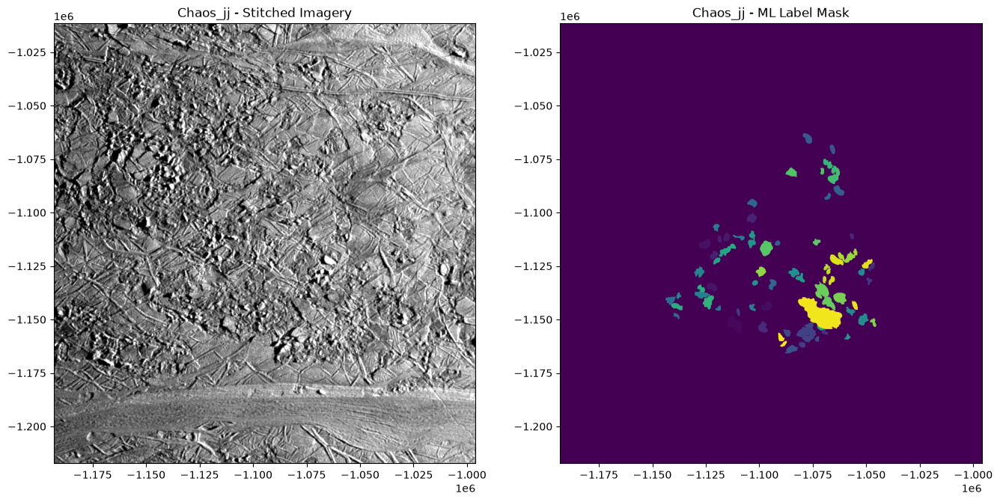

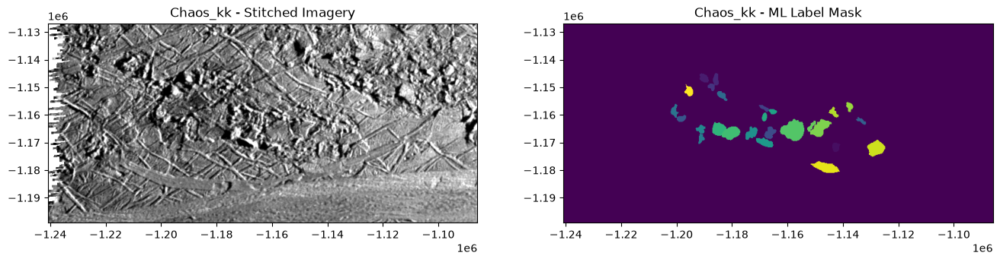

In [6]:
view_stitched_images_and_masks(
    geojson_dir="../data/raw/geojson_blocks",
    tiff_dir="../data/raw/tiff_images"
)

In [2]:
def analyze_block_sizes(mask_dir):
    """
    Analyze the pixel-size distribution of all block instances
    in the stitched mask GeoTIFFs.
    """

    records = []

    mask_paths = sorted(glob.glob(os.path.join(mask_dir, "*.tif")))

    for mask_path in mask_paths:

        region_name = os.path.splitext(
        os.path.basename(mask_path)
        )[0]

        with rasterio.open(mask_path) as src:
            mask = src.read(1)

        # every non-zero value represents one block
        instance_ids = np.unique(mask)
        instance_ids = instance_ids[instance_ids != 0]

        print(
        f"{region_name}: "
        f"{mask.shape[1]} x {mask.shape[0]} px, "
        f"{len(instance_ids)} blocks"
        )

        for instance_id in instance_ids:

            rows, cols = np.where(mask == instance_id)

            if len(rows) == 0:
                continue

            xmin = cols.min()
            xmax = cols.max()

            ymin = rows.min()
            ymax = rows.max()

            # +1 because pixel coordinates are inclusive
            width = xmax - xmin + 1
            height = ymax - ymin + 1

            area = len(rows)
 
            characteristic_size = np.sqrt(width * height)

            records.append({
            "region": region_name,
            "instance_id": int(instance_id),
            "width_px": width,
            "height_px": height,
            "bbox_area_px": width * height,
            "mask_area_px": area,
            "characteristic_size_px": characteristic_size,
            })

    df = pd.DataFrame(records)

    return df

In [6]:
mask_dir = "../data/preprocessed/masks"

df = analyze_block_sizes(mask_dir)

print(df.head())

Chaos_A: 1813 x 2041 px, 246 blocks
Chaos_B: 875 x 952 px, 91 blocks
Chaos_C: 789 x 989 px, 90 blocks
Chaos_Co: 1715 x 2177 px, 155 blocks
Chaos_D: 740 x 635 px, 73 blocks
Chaos_E: 1375 x 1030 px, 89 blocks
Chaos_F: 958 x 916 px, 39 blocks
Chaos_G: 1021 x 1091 px, 40 blocks
Chaos_H: 670 x 840 px, 21 blocks
Chaos_I: 1293 x 1289 px, 66 blocks
Chaos_aa: 1986 x 2025 px, 210 blocks
Chaos_bb: 2791 x 3282 px, 315 blocks
Chaos_dd: 1419 x 1271 px, 54 blocks
Chaos_ee: 892 x 783 px, 43 blocks
Chaos_ff: 793 x 822 px, 48 blocks
Chaos_gg: 1631 x 1522 px, 111 blocks
Chaos_hh: 2017 x 1499 px, 112 blocks
Chaos_ii: 2107 x 1660 px, 151 blocks
Chaos_jj: 1408 x 1470 px, 85 blocks
Chaos_kk: 1107 x 517 px, 26 blocks
    region  instance_id  width_px  height_px  bbox_area_px  mask_area_px  \
0  Chaos_A            1        23         25           575           199   
1  Chaos_A            2        16         13           208           113   
2  Chaos_A            3         2          2             4           

In [7]:
mask_dir = "../data/preprocessed_plates/masks"

df_plates = analyze_block_sizes(mask_dir)

print(df_plates.head())

Chaos_A: 1671 x 1893 px, 60 blocks
Chaos_B: 681 x 733 px, 19 blocks
Chaos_C: 789 x 824 px, 48 blocks
Chaos_Co: 1715 x 2177 px, 149 blocks
Chaos_D: 260 x 242 px, 2 blocks
Chaos_E: 224 x 269 px, 4 blocks
Chaos_F: 928 x 696 px, 14 blocks
Chaos_G: 874 x 971 px, 19 blocks
Chaos_H: 543 x 430 px, 5 blocks
Chaos_I: 1251 x 1259 px, 38 blocks
Chaos_aa: 1882 x 1539 px, 31 blocks
Chaos_bb: 2667 x 3118 px, 95 blocks
Chaos_dd: 1096 x 1271 px, 23 blocks
Chaos_ee: 696 x 552 px, 9 blocks
Chaos_ff: 793 x 822 px, 24 blocks
Chaos_gg: 1514 x 1517 px, 62 blocks
Chaos_hh: 1936 x 1499 px, 40 blocks
Chaos_ii: 1948 x 1422 px, 43 blocks
Chaos_jj: 1015 x 1241 px, 31 blocks
Chaos_kk: 893 x 280 px, 8 blocks
    region  instance_id  width_px  height_px  bbox_area_px  mask_area_px  \
0  Chaos_A            1         2          1             2             2   
1  Chaos_A            2        29         34           986           645   
2  Chaos_A            3        27         32           864           550   
3  Chaos_

In [13]:
percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]

summary = pd.DataFrame({
"percentile": percentiles,
"width_px": np.percentile(
df["width_px"], percentiles
),
"height_px": np.percentile(
df["height_px"], percentiles
),
"characteristic_size_px": np.percentile(
df["characteristic_size_px"], percentiles
)
})

print(summary.round(1))

   percentile  width_px  height_px  characteristic_size_px
0           1       1.7        2.0                     1.6
1           5       9.0       12.0                    11.4
2          10      10.0       13.0                    12.0
3          25      12.0       15.0                    13.7
4          50      16.0       19.0                    16.9
5          75      22.0       25.0                    23.2
6          90      30.0       35.0                    31.8
7          95      38.0       42.0                    38.4
8          99      62.0       59.3                    57.3
